## **Trabajo Práctico Final: Telco Churn**
____
__Universidad Tecnológica Nacional, Buenos Aires__\
__Ingeniería Industrial__\
__Ciencia de Datos - Curso I5571__
____
**Notebook 1 de 3: Análisis Exploratorio de Datos (EDA)**

**Grupo 6**

| Legajo | Integrante |
|---|---|
| 1764111 | Guillermo Inostroza |
| 1772752 | Erik Yuji Tanaka |
| 1593973 | Iñaki Hegoburu |
| 2042873 | Julián Longo |

# 1. Objetivo

Telco NN quiere anticipar qué clientes se van a dar de baja (`Churn` = Yes/No). Contamos con 7.043 clientes y 21 variables: datos demográficos, servicios contratados, contrato, forma de pago y facturación. Es un problema de clasificación binaria supervisada.

Este notebook describe el dataset, identifica sus problemas y las variables asociadas con la baja, y deja tomadas y justificadas las 18 decisiones de limpieza, preprocesamiento y evaluación que usan los otros dos notebooks del trabajo.

| Sección | Qué hacemos | Por qué |
|---|---|---|
| 2. Librerías y configuración | Fijamos librerías, semilla, rutas, paleta y grupos de variables | Que el resultado se reproduzca en otra computadora |
| 3. Carga de datos | Leemos el CSV sin modificarlo | Conservar el original como referencia de cada transformación |
| 4. Calidad de los datos | Revisamos identificadores, duplicados, tipos, dominio y reglas entre columnas (decisiones 1 a 3) | Saber qué corregir y qué dependencias permiten deducir faltantes |
| 5. Variable objetivo y partición | Medimos el balance de clases, fijamos la métrica y separamos train y test (decisiones 4, 13 y 14) | El desbalance condiciona la métrica, y separar antes de explorar evita decidir mirando el test |
| 6. Valores faltantes | Cuantificamos los faltantes, estudiamos su patrón y mecanismo, recuperamos lo deducible y definimos cómo imputar el resto (decisiones 5 a 8) | Solo el 12% de los clientes tiene la fila completa |
| 7. Análisis univariado | Describimos la distribución de cada variable en train (decisiones 9 y 10) | Define outliers, escalado y transformaciones |
| 8. Análisis bivariado | Medimos la asociación de cada variable con el churn y fijamos los costos de error (decisiones 17 y 18) | Identifica las variables relevantes y el umbral de decisión |
| 9. Análisis multivariado | Buscamos redundancias, interacciones y variables derivadas (decisiones 11, 12, 15 y 16) | Anticipa colinealidad, codificación y PCA |
| 10. Conclusiones | Resumimos hallazgos, registramos las 18 decisiones y listamos lo que queda para el modelado | Es lo que heredan los notebooks de manipulación y de machine learning |
| 11. Referencias | Bibliografía citada | |

**Los tres notebooks.** Este EDA se ejecuta primero: lee `data/telco_churn_clusterai.csv`, guarda la partición train/test en `data/particion_train_test.csv` y sus figuras en `figuras/`. Después, `clusterai_guillermo_inostroza_manipulacion.ipynb` aplica las decisiones que van antes del pipeline y guarda `data/telco_manipulado.csv`, y `clusterai_guillermo_inostroza_machine_learning.ipynb` arma el pipeline y evalúa los modelos. Las rutas son relativas a la carpeta del notebook.

Cada decisión va en un recuadro numerado con su justificación. Los otros dos notebooks las citan por ese número. La numeración sigue el orden del pipeline, de la limpieza a la evaluación, y no el orden de lectura; por eso algunas aparecen fuera de secuencia, como la 13 en la sección 5.1. Antes de cada celda de código explicamos qué hace, por qué la necesitamos y qué esperamos ver en la salida; cuando el resultado necesita lectura, lo interpretamos debajo.

# 2. Librerías y configuración

Antes de analizar dejamos fijo todo lo que el resto del notebook da por supuesto: las librerías, la semilla, las rutas, los colores y los grupos de variables. Lo separamos en cuatro bloques chicos para explicar cada uno.

## 2.1 Librerías

Usamos `pandas` y `numpy` para manipular tablas y hacer cálculos, `matplotlib` y `seaborn` para graficar y `scipy.stats` para los tests estadísticos (chi-cuadrado, Mann-Whitney e intervalos de Wilson). De `scikit-learn` (Pedregosa et al., 2011) tomamos solo lo que necesita el EDA: la partición train/test, la validación cruzada y una regresión logística con imputación y escalado. Esa regresión aparece en la sección 6.3, donde intentamos predecir qué datos faltan; el modelado del churn queda para el notebook de machine learning.

La celda imprime la versión de Python y de cada librería. Si alguien ejecuta el notebook con otras versiones y algún número cambia, esa línea permite rastrear la causa. En nuestra ejecución esperamos Python 3.14 con pandas 3.0 y scikit-learn 1.9.

In [1]:
import os                                                    # rutas relativas
import platform                                              # versión de Python
from itertools import combinations                           # pares de variables

import numpy as np                                           # cálculo numérico
import pandas as pd                                          # tablas de datos
import matplotlib                                            # librería base de gráficos
import matplotlib.ticker                                     # formato de ejes en porcentaje
import matplotlib.pyplot as plt                              # figuras
from matplotlib.colors import LinearSegmentedColormap        # escalas de color propias
import seaborn as sns                                        # gráficos estadísticos
import scipy                                                 # para imprimir la versión
from scipy import stats                                      # chi-cuadrado, Mann-Whitney y Wilson
import sklearn                                               # para imprimir la versión
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score   # split y CV
from sklearn.pipeline import make_pipeline                   # encadena pasos
from sklearn.impute import SimpleImputer                     # completa NaN
from sklearn.preprocessing import StandardScaler             # estandariza
from sklearn.linear_model import LogisticRegression          # regresión logística

print('Python', platform.python_version(), '|',   # versiones, para poder reproducir el resultado
      ' | '.join(f'{lib.__name__} {lib.__version__}' for lib in [pd, np, matplotlib, sns, scipy, sklearn]))   # librería y versión

Python 3.14.6 | pandas 3.0.3 | numpy 2.4.6 | matplotlib 3.11.0 | seaborn 0.13.2 | scipy 1.18.0 | sklearn 1.9.0


## 2.2 Semilla y rutas

Varios pasos del trabajo usan números aleatorios: la partición train/test, los cortes de la validación cruzada y el bootstrap de algunos intervalos. Fijamos la semilla (`SEED = 42`) para que esos pasos den siempre el mismo resultado y cualquiera que ejecute el notebook obtenga los números que informamos. Es la misma semilla en los tres notebooks del trabajo, así que la partición y los folds de validación coinciden entre ellos.

Las rutas son relativas a la carpeta del notebook. El CSV original se lee de `data/`, la partición se guarda en la misma carpeta y las figuras del informe van a `figuras/`, que se crea si no existe. De este modo el notebook corre en otra computadora sin editar rutas. La celda no produce salida; la configuración completa se imprime al final de la sección 2.4.

In [2]:
SEED = 42                                                   # semilla única para todo el TP
RUTA_DATOS = os.path.join('data', 'telco_churn_clusterai.csv')         # dataset original
RUTA_PARTICION = os.path.join('data', 'particion_train_test.csv')      # partición que leen los otros notebooks
CARPETA_FIGURAS = 'figuras'                                  # figuras del informe
os.makedirs(CARPETA_FIGURAS, exist_ok=True)                  # la creo si no existe

## 2.3 Paleta y estilo de los gráficos

Definimos los colores una sola vez para que todas las figuras sean consistentes. El churn usa siempre el mismo par: azul para los clientes que se quedan y naranja para los que se van. Así el lector no tiene que volver a la leyenda en cada gráfico, y el par se distingue también con las formas más comunes de daltonismo.

Sumamos dos escalas de color. La de riesgo va de blanco a naranja oscuro y se usa para magnitudes que van de 0 a un máximo, como tasas de churn o V de Cramér. La divergente va de naranja a azul y se usa para correlaciones entre -1 y +1, con el blanco en 0. También fijamos cómo muestra pandas las tablas (todas las columnas, 3 decimales) y definimos `guardar_figura`, que exporta cada gráfico en PNG a 150 dpi para el informe. La celda no produce salida.

In [3]:
AZUL_UTN, AZUL_OSCURO, CELESTE, NARANJA, GRIS = '#1C6094', '#0B2E4F', '#7FB3D5', '#EE8D35', '#6B7B8C'   # paleta
CMAP_RIESGO = LinearSegmentedColormap.from_list('riesgo', ['#FFFFFF', '#F9D9B9', NARANJA, '#A34E0C'])    # 0 a alto
CMAP_DIVERGENTE = LinearSegmentedColormap.from_list('divergente', [NARANJA, '#FFFFFF', AZUL_UTN])        # -1 a +1
sns.set_theme(style='whitegrid', context='notebook', palette=[AZUL_UTN, NARANJA, CELESTE, AZUL_OSCURO, GRIS])   # estilo y paleta
plt.rcParams.update({'axes.titleweight': 'bold', 'axes.titlecolor': AZUL_OSCURO,      # títulos en negrita
                     'axes.edgecolor': '#B8C4CF', 'grid.color': '#E3E9EF'})          # bordes y grilla suaves
COLORES_CHURN = {'No': AZUL_UTN, 'Yes': NARANJA}             # azul = se queda, naranja = se va
pd.set_option('display.max_columns', 40)                     # ver todas las columnas
pd.set_option('display.float_format', '{:.3f}'.format)       # 3 decimales


def guardar_figura(nombre):   # guarda la figura actual en figuras/
    # PNG a 150 dpi para el informe
    plt.savefig(os.path.join(CARPETA_FIGURAS, nombre + '.png'), dpi=150, bbox_inches='tight')   # recorto los márgenes sobrantes

## 2.4 Nombres de columnas y grupos de variables

Agrupamos las columnas según el papel que cumplen, porque cada grupo recibe herramientas distintas en todo el notebook.

- `customerID` (`COL_ID`) es solo un identificador. Toma un valor distinto en cada cliente, así que no describe ninguna característica compartida con otros. Un modelo que lo usara como predictora podría memorizar qué códigos se dieron de baja, y esa regla no sirve para un cliente nuevo, cuyo código nunca vio. Lo conservamos para guardar la partición y para identificar a los mismos clientes en los tres notebooks.
- `Churn` (`TARGET`) es la variable objetivo. Registra si el cliente se dio de baja, que es lo que la empresa quiere anticipar. Las demás columnas son candidatas a predictoras.
- Las numéricas (`COLS_NUM`) son cantidades con orden y distancia: meses de antigüedad, cargo mensual y total facturado. Tiene sentido promediarlas, medir su desvío y escalarlas.
- Las categóricas (`COLS_CAT`) indican a qué grupo pertenece el cliente, como el tipo de contrato o el medio de pago. Se resumen con frecuencias y tasas, se comparan con chi-cuadrado y, para el modelo, se codifican como dummies. `SeniorCitizen` viene como 0/1, pero indica una categoría (jubilado o no), por eso va en este grupo.
- Los servicios adicionales (`ADICIONALES`) son seis categóricas: seguridad online, backup, protección del equipo, soporte técnico y dos de streaming. Solo existen si el cliente tiene internet; sin internet valen "No internet service". Tenerlos en una lista facilita controlar esa regla (sección 4.2), deducir faltantes (sección 6.4) y contar cuántos contrata cada cliente (sección 9.4).

La celda termina imprimiendo la configuración. Esperamos 3 numéricas y 16 categóricas, 6 de ellas adicionales; con el identificador y el objetivo suman las 21 columnas del diccionario.

In [4]:
COL_ID, TARGET = 'customerID', 'Churn'                       # identificador y variable objetivo
COLS_NUM = ['tenure', 'MonthlyCharges', 'TotalCharges']      # numéricas
ADICIONALES = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',   # servicios que solo existen
               'TechSupport', 'StreamingTV', 'StreamingMovies']        # si el cliente tiene internet
COLS_CAT = (['gender', 'SeniorCitizen', 'Partner', 'Dependents',       # demográficas
             'PhoneService', 'MultipleLines', 'InternetService'] + ADICIONALES +   # servicios
            ['Contract', 'PaperlessBilling', 'PaymentMethod'])         # cuenta

print('Semilla:', SEED)                                      # la misma en los tres notebooks
print('Rutas | datos:', RUTA_DATOS, '| partición:', RUTA_PARTICION, '| figuras:', CARPETA_FIGURAS)   # relativas al notebook
print('Identificador:', COL_ID, '| objetivo:', TARGET)       # columnas que no son predictoras
print(f'Numéricas: {len(COLS_NUM)} | categóricas: {len(COLS_CAT)} (de ellas, {len(ADICIONALES)} adicionales) | '   # cantidad por tipo
      f'total con identificador y objetivo: {len(COLS_NUM) + len(COLS_CAT) + 2}')   # tienen que ser 21

Semilla: 42
Rutas | datos: data/telco_churn_clusterai.csv | partición: data/particion_train_test.csv | figuras: figuras
Identificador: customerID | objetivo: Churn
Numéricas: 3 | categóricas: 16 (de ellas, 6 adicionales) | total con identificador y objetivo: 21


# 3. Carga de datos

Leemos el CSV tal como viene, sin limpiar nada, y lo guardamos en `df_raw`. Ese DataFrame no se modifica en ningún paso: las transformaciones trabajan sobre copias, así siempre podemos volver al original para comparar.

La celda imprime la forma de la tabla, muestra las tres primeras filas y llama a `info()`, que lista cada columna con su cantidad de valores no nulos y el tipo que le asignó pandas. Esperamos 7.043 filas y las 21 columnas del diccionario. Los conteos de no nulos dan la primera medida de los faltantes, y los tipos muestran si pandas interpretó cada columna como corresponde.

In [5]:
df_raw = pd.read_csv(RUTA_DATOS)                             # CSV crudo
print('Shape:', df_raw.shape)                                # filas y columnas
display(df_raw.head(3))                                      # primeras filas, para ver el formato de cada columna
df_raw.info()                                               # no nulos y tipo de cada columna

Shape: (7043, 22)


,Unnamed: 0,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,7590-VHVEG,Female,NaN,Yes,No,1.000,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,NaN,Electronic check,29.850,29.85,No
1,1,5575-GNVDE,Male,0.000,No,No,34.000,Yes,No,NaN,Yes,No,Yes,No,No,No,One year,No,Mailed check,NaN,1889.5,No
2,2,3668-QPYBK,Male,0.000,No,No,2.000,NaN,No,NaN,Yes,NaN,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        7043 non-null   int64  
 1   customerID        7043 non-null   str    
 2   gender            6127 non-null   str    
 3   SeniorCitizen     6127 non-null   float64
 4   Partner           6127 non-null   str    
 5   Dependents        6127 non-null   str    
 6   tenure            6127 non-null   float64
 7   PhoneService      6127 non-null   str    
 8   MultipleLines     6127 non-null   str    
 9   InternetService   6127 non-null   str    
 10  OnlineSecurity    6127 non-null   str    
 11  OnlineBackup      6127 non-null   str    
 12  DeviceProtection  7043 non-null   str    
 13  TechSupport       7043 non-null   str    
 14  StreamingTV       7043 non-null   str    
 15  StreamingMovies   7043 non-null   str    
 16  Contract          5846 non-null   str    
 17  Paperl

Hay 22 columnas: las 21 del diccionario más `Unnamed: 0`. Los faltantes tienen una estructura muy regular: diez columnas tienen 6.127 valores (faltan 916) y cuatro tienen 5.846 (faltan 1.197). Hay dos problemas de tipo: `TotalCharges` se leyó como texto y `SeniorCitizen` como número. El dataset es casi todo categórico: 3 numéricas, 6 binarias, 10 nominales de 3 o 4 categorías y la variable objetivo.

# 4. Calidad de los datos

Esta sección usa el dataset completo, porque controla el registro y no mira la relación de las variables con el churn.

## 4.1 Identificadores, duplicados, tipos y dominio

La celda revisa cinco cosas en orden. Primero, si `Unnamed: 0` es una copia del índice que quedó al exportar el CSV y si `customerID` es único. Segundo, si hay clientes cargados dos veces con distinto ID, para lo cual comparamos las filas sin el identificador. Tercero, qué valores de `TotalCharges` impiden leerla como número: `pd.to_numeric(errors='coerce')` convierte lo que puede y deja `NaN` en el resto, y cruzamos esos casos con la antigüedad. Cuarto, las categorías de cada variable, porque una variante de escritura ("Yes" y "yes") sería otra categoría para el modelo. Por último, el rango de las numéricas, buscando meses fraccionarios o montos negativos.

Un duplicado pesaría doble en el análisis y en el modelo, y un valor imposible indicaría un error de registro. Esperamos no encontrar ninguno de los dos, y que los valores no numéricos de `TotalCharges` tengan una explicación de negocio.

In [6]:
print('Unnamed: 0 coincide con el índice:', (df_raw['Unnamed: 0'] == df_raw.index).all())   # copia del índice
print('customerID único por fila:', df_raw[COL_ID].is_unique)                               # sin IDs repetidos
print('Filas idénticas sin contar el ID:', df_raw.drop(columns=['Unnamed: 0', COL_ID]).duplicated().sum())   # duplicados de contenido

tc_numerico = pd.to_numeric(df_raw['TotalCharges'], errors='coerce')   # lo que no es número pasa a NaN
mask_tc_texto = tc_numerico.isna() & df_raw['TotalCharges'].notna()   # tenía texto pero no es número
print('\nValores no numéricos en TotalCharges:', df_raw.loc[mask_tc_texto, 'TotalCharges'].unique().tolist(),   # cuáles son
      '| cantidad:', mask_tc_texto.sum())   # cuántos son
print('Clientes con tenure = 0:', (df_raw['tenure'] == 0).sum(),   # clientes nuevos
      '| de ellos con TotalCharges en blanco:', (mask_tc_texto & (df_raw['tenure'] == 0)).sum())   # nuevos con el total en blanco
print('El restante tiene tenure faltante:', df_raw.loc[mask_tc_texto & (df_raw['tenure'] != 0), 'tenure'].isna().all())   # el blanco número 11

print('\nCategorías de cada variable:')   # buscamos variantes de escritura
for col in COLS_CAT + [TARGET]:   # recorro las categóricas y el churn
    print(f'  {col:16s}', sorted(df_raw[col].dropna().astype(str).unique()))   # valores distintos
print('tenure entero:', (df_raw['tenure'].dropna() % 1 == 0).all(),   # sin meses fraccionarios
      '| montos negativos:', (df_raw['MonthlyCharges'] < 0).sum() + (tc_numerico < 0).sum())   # montos imposibles
pd.DataFrame({'mín': [df_raw['tenure'].min(), df_raw['MonthlyCharges'].min(), tc_numerico.min()],   # mínimo de cada numérica
              'máx': [df_raw['tenure'].max(), df_raw['MonthlyCharges'].max(), tc_numerico.max()]},   # máximo de cada numérica
             index=COLS_NUM)                                 # rango de las numéricas

Unnamed: 0 coincide con el índice: True
customerID único por fila: True
Filas idénticas sin contar el ID: 0

Valores no numéricos en TotalCharges: [' '] | cantidad: 11
Clientes con tenure = 0: 10 | de ellos con TotalCharges en blanco: 10
El restante tiene tenure faltante: True

Categorías de cada variable:
  gender           ['Female', 'Male']
  SeniorCitizen    ['0.0', '1.0']
  Partner          ['No', 'Yes']
  Dependents       ['No', 'Yes']
  PhoneService     ['No', 'Yes']
  MultipleLines    ['No', 'No phone service', 'Yes']
  InternetService  ['DSL', 'Fiber optic', 'No']
  OnlineSecurity   ['No', 'No internet service', 'Yes']
  OnlineBackup     ['No', 'No internet service', 'Yes']
  DeviceProtection ['No', 'No internet service', 'Yes']
  TechSupport      ['No', 'No internet service', 'Yes']
  StreamingTV      ['No', 'No internet service', 'Yes']
  StreamingMovies  ['No', 'No internet service', 'Yes']
  Contract         ['Month-to-month', 'One year', 'Two year']
  PaperlessBilling ['N

,mín,máx
tenure,0.000,72.000
MonthlyCharges,18.700,118.750
TotalCharges,18.800,8684.800


`Unnamed: 0` es una copia del índice, `customerID` no se repite y no hay filas duplicadas. Los 11 valores no numéricos de `TotalCharges` son espacios en blanco. Los 10 clientes con `tenure = 0` tienen el total en blanco, y el undécimo tiene la antigüedad faltante. Son clientes que todavía no recibieron una factura, así que su total es 0. Las categorías están escritas siempre igual, `tenure` es entera de 0 a 72, `MonthlyCharges` va de 18,7 a 118,75 y `TotalCharges` de 18,8 a 8.684,8: no aparecen valores imposibles.

## 4.2 Coherencia entre columnas

Varias columnas dependen unas de otras por definición. `MultipleLines` dice "No phone service" si y solo si `PhoneService = No`, y los 6 adicionales dicen "No internet service" si y solo si `InternetService = No`. `TotalCharges` debería aproximarse a `tenure × MonthlyCharges`, porque es lo facturado mes a mes durante la vida del cliente. Si estas reglas se cumplen siempre, sirven para deducir faltantes (sección 6.4).

La celda cuenta las contradicciones de cada regla. En telefonía, las filas donde `PhoneService = No` y "No phone service" no coinciden. En internet, los clientes sin internet con algún adicional en Yes o No, los clientes con internet marcados "No internet service" y las filas que mezclan ambos valores. Después cruza teléfono con tipo de internet y, en los clientes con las tres numéricas y antigüedad positiva, resume el cociente `TotalCharges / (tenure × MonthlyCharges)`. Esperamos cero contradicciones en las dos primeras reglas y un cociente centrado en 1.

In [7]:
tel = df_raw[['PhoneService', 'MultipleLines']].dropna()                    # filas con ambas columnas
print(f'Telefonía: {((tel["PhoneService"] == "No") != (tel["MultipleLines"] == "No phone service")).sum()} '   # contradicciones
      f'contradicciones en {len(tel)} filas')   # sobre cuántas filas
inet = df_raw.dropna(subset=['InternetService'])                            # filas con InternetService
marca_nis = inet[ADICIONALES] == 'No internet service'                      # adicional = "No internet service"
observado = inet[ADICIONALES].notna()                                       # adicional informado
sin_inet = inet['InternetService'] == 'No'                                  # no tiene internet
print('Internet: sin internet con un adicional Yes/No:', (sin_inet & (observado & ~marca_nis).any(axis=1)).sum(),   # contradicciones
      '| con internet marcado "No internet service":', (~sin_inet & marca_nis.any(axis=1)).sum(),   # segunda contradicción posible
      '| filas que mezclan:', (marca_nis.any(axis=1) & (observado & ~marca_nis).any(axis=1)).sum())   # tercera contradicción posible
print(pd.crosstab(df_raw['PhoneService'], df_raw['InternetService']))     # teléfono x internet

completos = df_raw.assign(TotalCharges=tc_numerico).dropna(subset=COLS_NUM)   # las tres numéricas presentes
completos = completos[completos['tenure'] > 0]                             # sin dividir por cero
ratio = completos['TotalCharges'] / (completos['tenure'] * completos['MonthlyCharges'])   # 1 si la regla es exacta
print(ratio.describe(percentiles=[0.05, 0.5, 0.95]).round(3).to_frame('TotalCharges / (tenure x MonthlyCharges)').T)   # resumen del cociente

Telefonía: 0 contradicciones en 5339 filas
Internet: sin internet con un adicional Yes/No: 0 | con internet marcado "No internet service": 0 | filas que mezclan: 0
InternetService   DSL  Fiber optic    No
PhoneService                            
No                510            0     0
Yes              1330         2342  1168
                                            count  mean   std   min    5%  \
TotalCharges / (tenure x MonthlyCharges) 5078.000 1.001 0.051 0.690 0.924   

                                           50%   95%   max  
TotalCharges / (tenure x MonthlyCharges) 1.000 1.077 1.573  


Las reglas de telefonía e internet se cumplen sin excepciones, y "No internet service" aparece en los 6 adicionales a la vez o en ninguno. El cruce de teléfono e internet muestra una tercera regla, propia de la oferta comercial: los 510 clientes sin teléfono tienen todos DSL. La regla de facturación es aproximada: el cociente tiene mediana 1,000 y desvío 0,05, y el 90% de los clientes queda entre 0,92 y 1,08. No da exactamente 1 porque `MonthlyCharges` es el cargo actual y el precio pudo cambiar durante la vida del cliente.

> **Decisiones 1, 2 y 3:** eliminar `Unnamed: 0` y conservar `customerID` solo como identificador (para la partición), nunca como predictora. Convertir `TotalCharges` a número: los 11 blancos pasan a `NaN` y se completan con 0 en la sección 6.4. Pasar `SeniorCitizen` de 0/1 a No/Yes y crear `churn_num` (1 = se fue), cuyo promedio es la tasa de churn.
>
> **Justificación:** `Unnamed: 0` repite el número de fila. Un identificador único por cliente le permitiría a un modelo memorizar qué códigos se fueron, y esa regla no vale para un cliente nuevo. Un monto guardado como texto no se puede promediar ni escalar, y los blancos tienen una explicación de negocio, no son errores de carga (Géron, 2022, cap. 2; VanderPlas, 2016, cap. 3, *Handling Missing Data*). Con `SeniorCitizen` en No/Yes, todas las binarias reciben el mismo tratamiento.

La celda aplica las tres decisiones sobre una copia, `df`: quita `Unnamed: 0`, reemplaza `TotalCharges` por su versión numérica, recodifica `SeniorCitizen` y agrega `churn_num`. Como el promedio de una variable 0/1 es la proporción de unos, `churn_num.mean()` da directamente la tasa de churn. Esperamos 22 columnas (las 21 del diccionario más `churn_num`) y 11 `NaN` en `TotalCharges`. Los faltantes de `SeniorCitizen` tienen que seguir como `NaN` después de recodificar, y las tres numéricas tienen que quedar como `float64`.

In [8]:
df = df_raw.drop(columns=['Unnamed: 0']).copy()                          # decisión 1: sin la columna índice
df['TotalCharges'] = tc_numerico                                         # decisión 2: texto a número
df['SeniorCitizen'] = df['SeniorCitizen'].map({0.0: 'No', 1.0: 'Yes'})   # decisión 3: 0/1 a No/Yes
df['churn_num'] = (df[TARGET] == 'Yes').astype(int)                      # 1 si se fue: su media es la tasa
print('Shape de df:', df.shape)                                          # las 21 del diccionario más churn_num
print('NaN en TotalCharges:', df['TotalCharges'].isna().sum(),           # los 11 blancos
      f"| tasa de churn: {df['churn_num'].mean():.1%}")                  # promedio de churn_num
print('SeniorCitizen:', df['SeniorCitizen'].value_counts(dropna=False).to_dict())   # los NaN siguen siendo NaN
df[COLS_NUM + ['SeniorCitizen', 'churn_num']].dtypes                     # verifico los tipos

Shape de df: (7043, 22)
NaN en TotalCharges: 11 | tasa de churn: 26.5%
SeniorCitizen: {'No': 5137, 'Yes': 990, nan: 916}


tenure            float64
MonthlyCharges    float64
TotalCharges      float64
SeniorCitizen         str
churn_num           int64
dtype: object

# 5. Variable objetivo y partición train/test

## 5.1 Balance de clases

Contamos cuántos clientes hay en cada clase de `Churn`, calculamos su porcentaje y lo graficamos con una barra por clase. La proporción de bajas condiciona qué métricas tienen sentido: si una clase es mucho más chica, un modelo puede acertar casi siempre sin detectar a ninguno de sus casos. Usamos el dataset completo porque este dato hace falta para estratificar la partición de la sección 5.2. Esperamos una minoría de bajas.

       clientes      %
Churn                 
No         5174 73.463
Yes        1869 26.537


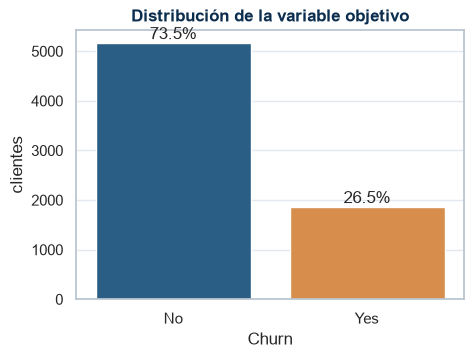

In [9]:
conteo = df[TARGET].value_counts()                             # clientes por clase
balance = pd.DataFrame({'clientes': conteo, '%': conteo / len(df) * 100})   # y su porcentaje
print(balance)                                                 # muestro la tabla

fig, ax = plt.subplots(figsize=(5, 3.5))                       # figura chica
sns.countplot(data=df, x=TARGET, hue=TARGET, palette=COLORES_CHURN, order=['No', 'Yes'],   # barras de churn
              legend=False, ax=ax)                             # una barra por clase con su color
for barra, pct in zip(ax.patches, balance.loc[['No', 'Yes'], '%']):   # recorro barra y porcentaje
    ax.annotate(f'{pct:.1f}%', (barra.get_x() + barra.get_width() / 2, barra.get_height()),   # posición: centro y tope de la barra
                ha='center', va='bottom')                      # escribo el % arriba de la barra
ax.set_title('Distribución de la variable objetivo')          # título
ax.set_ylabel('clientes')                                      # eje y
guardar_figura('balance_clases')                               # guardo el PNG
plt.show()                                                     # muestro la figura

Se van 1.869 de los 7.043 clientes (26,5%). El desbalance no es extremo, pero alcanza para que la accuracy sea engañosa: el clasificador que responde siempre "nadie se va" acierta el 73,5% sin aprender nada (James et al., 2023, sec. 4.4.2).

> **Decisión 13:** comparar y elegir modelos por ROC-AUC con validación cruzada. Fijar el umbral de decisión con una matriz de costos, elegido con validación cruzada sobre train y nunca con test. Reportar matriz de confusión, recall y precisión sobre los clientes que se van. Usar tres líneas de base: "nadie se va" (accuracy 73,5%, AUC 0,5), "oferta a todos" (contactar a todos los clientes, sin modelo) y una regresión logística sin ajuste de hiperparámetros. No balancear las clases; `class_weight='balanced'` queda solo como alternativa.
>
> **Justificación:** el AUC mide cómo ordena el modelo a los clientes por riesgo, sin depender del umbral. La curva ROC no cambia con el desbalance, porque cada una de sus tasas se calcula dentro de una clase (Murphy, 2022, sec. 5.1.4.4; Géron, 2022, cap. 3). Para decidir a quién contactar hace falta un umbral, y los dos errores no cuestan lo mismo: un churner no detectado se lleva sus ingresos, mientras que contactar a quien se iba a quedar cuesta una oferta. Con una matriz de costos, el umbral óptimo sale del cociente entre esos costos y no del 0,5 de `predict` (Murphy, 2022, sec. 5.1.2.2). La línea "oferta a todos" es la vara que tiene que superar un modelo cuando la oferta es barata frente a la pérdida. `class_weight` cambia sobre todo la escala de las probabilidades, que es lo que el umbral por costos resuelve de forma explícita. Esperamos que casi no mueva el AUC, pero es una hipótesis que se verifica en el notebook de machine learning.

## 5.2 Partición train/test

> **Decisiones 4 y 14:** separar ahora el 20% de los clientes como test, estratificado por `Churn` y con `random_state=42`, y guardar la partición en `data/particion_train_test.csv`. Desde aquí, todo lo que relaciona variables con el churn se calcula solo con train. En el notebook de machine learning los modelos se comparan con validación cruzada estratificada de 5 folds sobre train, y el test se usa una sola vez al final.
>
> **Justificación:** si exploramos el dataset completo, lo que vemos de los clientes de test influye en las decisiones y la métrica final sale optimista, el sesgo que Géron (2022, cap. 2, *Create a Test Set*) llama *data snooping*. La estratificación mantiene el 26,5% de churn en los dos conjuntos. Guardar la partición en un CSV garantiza que los otros notebooks usen exactamente los mismos clientes aunque cambie la versión de scikit-learn. La validación cruzada promedia 5 cortes de train y da el desvío entre ellos, así que la comparación depende menos de qué clientes cayeron en cada corte (James et al., 2023, cap. 5). Las secciones 4, 6.1 y 6.2 usan todo el dataset porque controlan el registro sin mirar el churn.

La celda parte los índices del DataFrame: 20% para test, estratificado por `Churn` y con la semilla fija. Arma una tabla que asigna cada `customerID` a train o test y la guarda en CSV. Si ya existía una partición guardada, antes comprueba que sea idéntica, para que una nueva ejecución no cambie los clientes de test sin aviso. Después imprime el tamaño y la tasa de churn de cada conjunto.

Por último estima con qué precisión va a medir el test el recall final. El recall es la proporción de churners que el modelo detecta, así que con `n` churners en test su error estándar es `√(p(1 - p) / n)`. Esperamos unos 5.600 clientes en train y 1.400 en test, ambos con 26,5% de churn.

In [10]:
idx_train, idx_test = train_test_split(df.index, test_size=0.2, stratify=df[TARGET], random_state=SEED)   # 80/20 estratificado
particion = pd.DataFrame({COL_ID: df[COL_ID], 'conjunto': 'train'})      # todos empiezan como train
particion.loc[idx_test, 'conjunto'] = 'test'                             # marco los de test
if os.path.exists(RUTA_PARTICION):                                       # si ya había una partición guardada
    assert pd.read_csv(RUTA_PARTICION).equals(particion), 'la partición guardada no coincide'   # tiene que ser la misma
particion.to_csv(RUTA_PARTICION, index=False, lineterminator='\n')       # la guardo (fin de línea fijo en cualquier sistema)
print(particion['conjunto'].value_counts().to_dict())   # tamaño de cada conjunto
print('% churn:', {n: float(round(df.loc[i, 'churn_num'].mean() * 100, 1)) for n, i in [('train', idx_train), ('test', idx_test)]})   # estratificación

n_churn_test = df.loc[idx_test, 'churn_num'].sum()                       # churners en test (fijado por la estratificación)
print('Churners en test:', n_churn_test, '| error estándar del recall:',   # precisión del recall final
      {p: float(round(np.sqrt(p * (1 - p) / n_churn_test), 3)) for p in [0.5, 0.7, 0.9]})   # raíz de p(1-p)/n

{'train': 5634, 'test': 1409}
% churn: {'train': 26.5, 'test': 26.5}
Churners en test: 374 | error estándar del recall: {0.5: 0.026, 0.7: 0.024, 0.9: 0.016}


Train queda con 5.634 clientes y test con 1.409, los dos con 26,5% de churn. El test tiene 374 churners, así que el recall final tiene un error estándar de 0,016 a 0,026 según su valor: un intervalo del 95% de unos ±3 a ±5 puntos. Diferencias menores entre modelos no se distinguen con el test, y por eso la comparación se hace con validación cruzada.

# 6. Valores faltantes

Es el problema principal del dataset. Lo tratamos en cinco pasos: cuántos faltan, con qué patrón, por qué mecanismo, cuánto se recupera por deducción y qué hacemos con el resto.

## 6.1 Cuántos faltan

Contamos los `NaN` por columna y por cliente. El primer conteo dice cuánto pierde cada variable; el segundo, cuántos clientes quedarían si descartáramos toda fila incompleta. La celda imprime cuántas columnas tienen faltantes, los porcentajes distintos que aparecen, el total de celdas vacías y la cantidad de filas completas. El gráfico muestra a la izquierda el porcentaje de faltantes por variable y a la derecha cuántos clientes tienen 0, 1, 2 o más datos faltantes. Usamos el dataset completo, porque describimos el registro sin mirar el churn. Esperamos los dos niveles de faltantes que anticipó `info()`.

Columnas con faltantes: 15 | niveles: [0.2, 13.0, 17.0] %
Celdas faltantes: 13959 | clientes con la fila completa: 844 (12.0%)


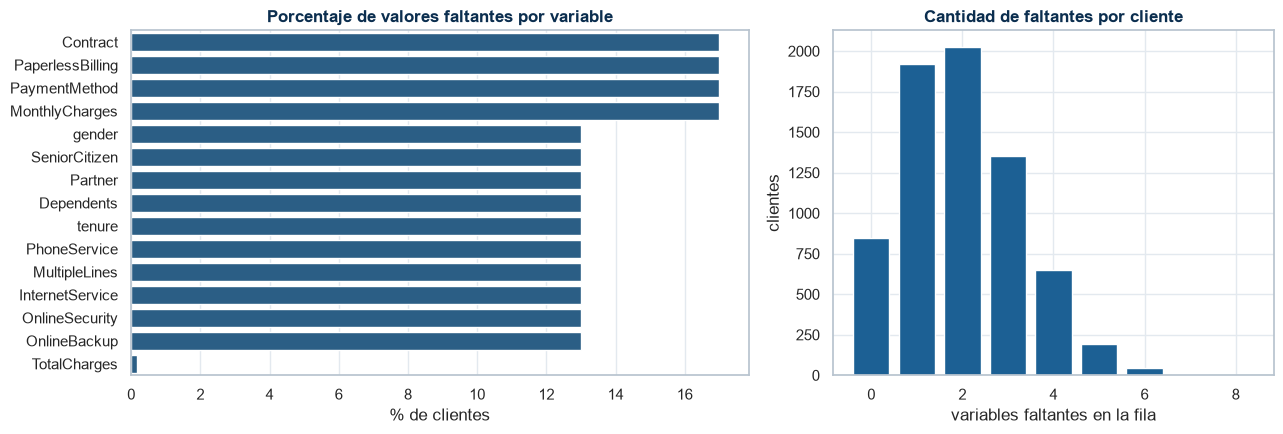

In [11]:
faltantes = df.isna().sum()                                            # NaN por columna
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)      # solo las que tienen
nan_por_fila = df.isna().sum(axis=1)                                   # NaN por cliente
print('Columnas con faltantes:', len(faltantes), '| niveles:', sorted(set((faltantes / len(df) * 100).round(1))), '%')   # porcentajes distintos
print(f'Celdas faltantes: {faltantes.sum()} | clientes con la fila completa: {(nan_por_fila == 0).sum()} '   # filas completas
      f'({(nan_por_fila == 0).mean():.1%})')   # como porcentaje

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1.4, 1]})   # dos paneles
sns.barplot(x=faltantes / len(df) * 100, y=faltantes.index, color=AZUL_UTN, ax=axes[0])   # % NaN por variable
axes[0].set_title('Porcentaje de valores faltantes por variable')   # título del panel izquierdo
axes[0].set_xlabel('% de clientes')                                 # eje x
axes[0].set_ylabel('')                                              # sin título en el eje y
conteo_filas = nan_por_fila.value_counts().sort_index()             # clientes por cantidad de NaN
axes[1].bar(conteo_filas.index, conteo_filas.values, color=AZUL_UTN)   # una barra por cantidad
axes[1].set_title('Cantidad de faltantes por cliente')              # título del panel derecho
axes[1].set_xlabel('variables faltantes en la fila')                # eje x
axes[1].set_ylabel('clientes')                                      # eje y
plt.tight_layout()                                                  # acomodo los paneles
guardar_figura('faltantes_por_variable')                            # guardo el PNG
plt.show()                                                          # muestro la figura

Quince columnas tienen faltantes. Una es `TotalCharges`, con los 11 blancos de la sección 4.1 (0,2%). Las otras catorce tienen faltantes en dos niveles exactos: 13,0% (916 clientes) en diez de ellas y 17,0% (1.197) en `Contract`, `PaperlessBilling`, `PaymentMethod` y `MonthlyCharges`. Esa regularidad sugiere un borrado artificial con una tasa fija por columna. Como los faltantes caen en filas distintas, solo el 12,0% de los clientes tiene la fila completa (844 de 7.043).

> **Decisión 5:** no eliminar filas con faltantes (`dropna`).
>
> **Justificación:** cada columna pierde a lo sumo el 17%, pero quitar las filas incompletas eliminaría al 88% de los clientes. Entre eliminar filas, eliminar variables o imputar (Géron, 2022, cap. 2, *Clean the Data*), con esta proporción solo la imputación conserva la información (James et al., 2023, sec. 12.3).

## 6.2 Patrón de los faltantes

Si los faltantes aparecieran juntos (por ejemplo, `tenure` y `MonthlyCharges` en los mismos clientes), habría un proceso común detrás. Lo medimos con la correlación entre los indicadores de faltante y con el cociente entre los clientes a los que les faltan dos datos y los que se esperarían por azar. Dejamos afuera `TotalCharges`, cuyos 11 casos ya tienen explicación.

Un indicador de faltante vale 1 si el dato falta y 0 si está. Si dos indicadores son independientes, la cantidad esperada de clientes sin ninguno de los dos datos es `n · p_a · p_b`, donde `p_a` y `p_b` son las proporciones de faltantes de cada variable. La celda calcula la correlación entre los 14 indicadores y el cociente entre lo observado y ese esperado en los 91 pares posibles. Esperamos correlaciones cercanas a 0 y cocientes cercanos a 1 si cada columna perdió sus datos por separado.

In [12]:
COLS_NAN = [c for c in faltantes.index if c != 'TotalCharges']         # faltantes "inyectados" (sin los 11 blancos)
indicadores = df[COLS_NAN].isna().astype(int)                          # 1 si falta
corr_vals = indicadores.corr().to_numpy()[np.triu_indices(len(COLS_NAN), 1)]   # correlación entre indicadores
p_nan = indicadores.mean()                                             # proporción de NaN de cada variable
obs_esp = [((indicadores[a] == 1) & (indicadores[b] == 1)).sum() / (len(df) * p_nan[a] * p_nan[b])   # observado / esperado de cada par
           for a, b in combinations(COLS_NAN, 2)]                      # ambos faltan: observado / esperado por azar
print(f'Máxima |correlación| entre indicadores: {np.abs(corr_vals).max():.3f}')   # independencia entre indicadores
print(f'Ambos faltan, observado/esperado en los {len(obs_esp)} pares: media {np.mean(obs_esp):.3f}, '   # co-ocurrencia
      f'de {min(obs_esp):.2f} a {max(obs_esp):.2f}')   # rango del cociente

Máxima |correlación| entre indicadores: 0.034
Ambos faltan, observado/esperado en los 91 pares: media 1.004, de 0.83 a 1.23


La correlación entre indicadores no pasa de 0,034 en valor absoluto, y en los 91 pares la cantidad de clientes con los dos datos faltantes es la que se espera por azar (cociente medio 1,004, entre 0,83 y 1,23). Que falte un dato no cambia la probabilidad de que falte otro.

## 6.3 Mecanismo de los faltantes (con train)

El tratamiento depende de si los faltantes son MCAR, MAR o MNAR (Murphy, 2022, sec. 1.5.5). Ningún test demuestra MCAR, pero sí se puede buscar evidencia en contra frente a MAR: si los faltantes dependieran de otras variables, los clientes sin el dato serían distintos de los que lo tienen. Lo miramos de tres formas, solo con train porque el resultado condiciona la imputación:

- **(a)** la tasa de churn con y sin el dato, con el p-valor y el IC 95% de cada diferencia y la potencia de la comparación (Cohen, 1988; James et al., 2023, sec. 13.1);
- **(b)** un test contra cada una de las demás variables, chi-cuadrado para las categóricas (Pearson, 1900) y Mann-Whitney para las numéricas (Mann y Whitney, 1947), con la corrección de Bonferroni (James et al., 2023, sec. 13.3.2);
- **(c)** una regresión logística que intenta predecir qué celdas faltan, evaluada por AUC con validación cruzada.

En MCAR la probabilidad de que falte un dato no depende de nada; en MAR depende de otras variables observadas, y en MNAR depende del propio valor que falta. La distinción importa porque una imputación simple, que ignora el mecanismo, solo es segura en el primer caso.

**(a) Churn con y sin el dato.** Para cada variable con faltantes separamos a los clientes de train en dos grupos, con y sin el dato, y comparamos su tasa de churn. La celda calcula también la diferencia mínima detectable: la menor brecha que un test de dos proporciones detectaría el 80% de las veces con α = 0,05. Vale `(1,96 + 0,84) · √(p(1 - p)(1/n₁ + 1/n₀))`, con `p` la tasa de churn de train. No es un test: mide la potencia, es decir, qué brecha habríamos visto con alta probabilidad si existiera. El test de cada diferencia va en la celda siguiente. Esta imprime el resumen; la tabla completa aparece al final de la parte (c).

In [13]:
train_orig = df.loc[idx_train]                                 # train con los faltantes originales
p_global = train_orig['churn_num'].mean()                      # tasa de churn de train
filas = []                                                     # (a) churn con y sin el dato
for col in COLS_NAN:   # recorro las variables con faltantes
    falta = train_orig[col].isna()                             # True si falta el dato
    n1, n0 = falta.sum(), (~falta).sum()                       # tamaño de cada grupo
    filas.append({'variable': col, 'churn % falta': train_orig.loc[falta, 'churn_num'].mean() * 100,   # churn con y sin el dato
                  'churn % no falta': train_orig.loc[~falta, 'churn_num'].mean() * 100,   # churn con el dato
                  'dif. mínima detectable (pp)': (1.96 + 0.84) * np.sqrt(p_global * (1 - p_global) * (1 / n1 + 1 / n0)) * 100})   # potencia del 80% con alfa 0,05
tabla_a = pd.DataFrame(filas).set_index('variable')   # tabla del punto (a)
tabla_a['diferencia (pp)'] = tabla_a['churn % falta'] - tabla_a['churn % no falta']   # diferencia en puntos
print(f'Clientes de train: {len(train_orig)} | tasa de churn: {p_global:.1%}')   # base de la comparación
print(f"Mayor |diferencia|: {tabla_a['diferencia (pp)'].abs().max():.1f} pp en {tabla_a['diferencia (pp)'].abs().idxmax()} | "   # la brecha más grande
      f"diferencia mínima detectable: {tabla_a['dif. mínima detectable (pp)'].min():.1f} a {tabla_a['dif. mínima detectable (pp)'].max():.1f} pp")   # rango del umbral

Clientes de train: 5634 | tasa de churn: 26.5%
Mayor |diferencia|: 3.4 pp en PaymentMethod | diferencia mínima detectable: 4.4 a 4.9 pp


La celda siguiente prueba cada diferencia. El p-valor sale de un chi-cuadrado de 2×2 entre el indicador de faltante y el churn, y el IC 95% de la aproximación normal para una diferencia de proporciones. Son 14 comparaciones, así que Bonferroni exige p < 0,05 / 14 ≈ 0,0036. Si los faltantes son MCAR, esperamos intervalos que contengan al 0 y ningún p-valor por debajo de ese umbral.

In [14]:
filas_ic = []                                                  # (a) test de cada diferencia, solo lectura
for var in COLS_NAN:                                           # recorro las variables con faltantes
    sin_dato = train_orig[var].isna()                          # True si falta el dato
    p1, p0 = train_orig.loc[sin_dato, 'churn_num'].mean(), train_orig.loc[~sin_dato, 'churn_num'].mean()   # tasa sin y con el dato
    ee = np.sqrt(p1 * (1 - p1) / sin_dato.sum() + p0 * (1 - p0) / (~sin_dato).sum())   # error estándar de la diferencia
    filas_ic.append({'variable': var, 'diferencia (pp)': (p1 - p0) * 100,   # la misma diferencia de tabla_a
                     'IC 95% inf. (pp)': (p1 - p0 - 1.96 * ee) * 100,   # límite inferior
                     'IC 95% sup. (pp)': (p1 - p0 + 1.96 * ee) * 100,   # límite superior
                     'p-valor': stats.chi2_contingency(pd.crosstab(sin_dato, train_orig['churn_num']), correction=False)[1]})   # chi-cuadrado 2x2
print(f'Bonferroni con {len(COLS_NAN)} comparaciones: p < {0.05 / len(COLS_NAN):.4f}')   # umbral corregido
pd.DataFrame(filas_ic).set_index('variable').round(3)          # muestro la tabla

Bonferroni con 14 comparaciones: p < 0.0036


,diferencia (pp),IC 95% inf. (pp),IC 95% sup. (pp),p-valor
variable,,,,
Contract,-0.011,-3.090,3.068,0.994
PaperlessBilling,0.403,-2.687,3.493,0.798
PaymentMethod,-3.368,-6.360,-0.375,0.032
MonthlyCharges,0.656,-2.440,3.753,0.676
gender,-2.157,-5.521,1.206,0.218
SeniorCitizen,2.541,-0.972,6.053,0.148
Partner,-2.079,-5.418,1.261,0.232
Dependents,0.947,-2.512,4.407,0.588
tenure,-1.462,-4.814,1.890,0.399


**(b) Tests contra las demás variables.** Para cada variable con faltantes comparamos a los clientes con y sin el dato en todas las demás: con chi-cuadrado si la otra es categórica y con Mann-Whitney si es numérica. Mann-Whitney compara rangos y no supone normalidad, lo que conviene con distribuciones como la bimodal de `MonthlyCharges`. Con tantos tests, algunos dan p < 0,05 por azar: con α = 0,05 esperamos un 5% de falsos positivos. Bonferroni lo corrige exigiendo p < 0,05 dividido por la cantidad de tests. Si los faltantes son MCAR, esperamos una cantidad de significativos parecida a la del azar y ninguno con Bonferroni.

In [15]:
p_valores = []                                                 # (b) tests contra todas las variables
for col in COLS_NAN:   # recorro las variables con faltantes
    falta = train_orig[col].isna()   # True si falta el dato
    for otra in COLS_CAT + [TARGET]:                           # chi-cuadrado contra cada categórica y el churn
        if otra != col:   # salvo contra sí misma
            p_valores.append(stats.chi2_contingency(pd.crosstab(falta, train_orig[otra]), correction=False)[1])   # p-valor del chi-cuadrado
    for num in COLS_NUM:                                       # Mann-Whitney contra cada numérica
        if num != col:   # salvo contra sí misma
            p_valores.append(stats.mannwhitneyu(train_orig.loc[falta, num].dropna(), train_orig.loc[~falta, num].dropna()).pvalue)   # p-valor de Mann-Whitney
p_valores = np.array(p_valores)   # paso la lista a array
print(f'(b) Tests: {len(p_valores)} | p < 0,05: {(p_valores < 0.05).sum()} (por azar se esperan {0.05 * len(p_valores):.1f}) '   # recuento de significativos
      f'| con Bonferroni (p < {0.05 / len(p_valores):.5f}): {(p_valores < 0.05 / len(p_valores)).sum()}')   # significativos corregidos

(b) Tests: 266 | p < 0,05: 10 (por azar se esperan 13.3) | con Bonferroni (p < 0.00019): 0


Para saber qué pares dieron p < 0,05, la celda siguiente reconstruye las etiquetas de los 266 tests en el mismo orden del bucle anterior y lista los significativos sin corregir. No repite ningún test: solo pone nombre a los p-valores ya calculados.

In [16]:
pares_b = [(c, o) for c in COLS_NAN for o in COLS_CAT + [TARGET] + COLS_NUM if o != c]   # mismo orden que el bucle de (b)
assert len(pares_b) == len(p_valores)                          # una etiqueta por test
significativos = pd.DataFrame(pares_b, columns=['variable con faltantes', 'contra']).assign(**{'p-valor': p_valores})   # cada test con su p-valor
significativos[significativos['p-valor'] < 0.05].sort_values('p-valor').reset_index(drop=True).style.format({'p-valor': '{:.4f}'})   # los significativos sin corregir

,variable con faltantes,contra,p-valor
0,OnlineSecurity,Dependents,0.0013
1,PaymentMethod,OnlineSecurity,0.0025
2,PaperlessBilling,Partner,0.0025
3,OnlineSecurity,tenure,0.0198
4,PaymentMethod,Churn,0.0322
5,PaymentMethod,InternetService,0.0410
6,tenure,Dependents,0.0415
7,Partner,TechSupport,0.0457
8,PhoneService,PaperlessBilling,0.0462
9,MultipleLines,Contract,0.0477


**(c) Predecir qué celdas faltan.** Los tests de (b) miran una variable por vez, y un faltante podría depender de una combinación de ellas. Para cada variable con faltantes entrenamos una regresión logística que, a partir del resto de las columnas y del churn, intenta predecir si ese dato falta. La evaluamos con el AUC en validación cruzada estratificada de 5 folds. Un AUC de 0,5 equivale a adivinar al azar; cuanto más se acerca a 1, más predecible es el faltante y más lejos estamos de MCAR.

Las categóricas entran como dummies, y un `NaN` deja todas sus dummies en 0. Las numéricas entran con sus `NaN`, que el pipeline imputa con la mediana antes de estandarizar; imputación, escalado y modelo se ajustan de nuevo en cada fold. Esperamos AUC cercanos a 0,5. La tabla final reúne los resultados de (a) y (c).

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # (c) predecir el faltante
for col in COLS_NAN:   # recorro las variables con faltantes
    otras_cat = [c for c in COLS_CAT if c != col] + [TARGET]   # predictoras categóricas
    X = pd.concat([pd.get_dummies(train_orig[otras_cat], dtype=float),     # un NaN deja todas las dummies en 0
                   train_orig[[c for c in COLS_NUM if c != col]]], axis=1)  # numéricas con sus NaN
    modelo = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000))   # imputar, escalar y logística en cada fold
    tabla_a.loc[col, 'AUC predecir el faltante'] = cross_val_score(modelo, X, train_orig[col].isna().astype(int),   # AUC medio en 5 folds
                                                                    cv=cv, scoring='roc_auc').mean()   # promedio de los 5 folds
print(f"AUC para predecir el faltante: de {tabla_a['AUC predecir el faltante'].min():.2f} a {tabla_a['AUC predecir el faltante'].max():.2f}")   # rango del AUC
tabla_a.round(3)   # muestro la tabla

AUC para predecir el faltante: de 0.48 a 0.54


,churn % falta,churn % no falta,dif. mínima detectable (pp),diferencia (pp),AUC predecir el faltante
variable,,,,,
Contract,26.526,26.537,4.399,-0.011,0.481
PaperlessBilling,26.870,26.467,4.401,0.403,0.507
PaymentMethod,23.734,27.102,4.403,-3.368,0.507
MonthlyCharges,27.081,26.425,4.401,0.656,0.503
gender,24.658,26.815,4.904,-2.157,0.491
SeniorCitizen,28.748,26.207,4.913,2.541,0.509
Partner,24.731,26.810,4.865,-2.079,0.475
Dependents,27.360,26.412,4.901,0.947,0.491
tenure,25.267,26.729,4.854,-1.462,0.508


- **(a)** La mayor diferencia es la de `PaymentMethod`: los clientes sin el dato tienen 3,4 puntos menos de churn (IC 95% de -6,4 a -0,4; p = 0,032). Con 14 comparaciones, Bonferroni exige p < 0,0036 y no llega. En las otras 13 variables el intervalo contiene al 0. La potencia acota lo que podría quedar oculto: una brecha de 4,4 pp o más se habría detectado con 80% de probabilidad en las columnas con 17% de faltantes, y una de 4,9 pp en las de 13%. Esto no prueba que las tasas sean idénticas, pero alcanza para decidir la imputación.
- **(b)** De 266 tests, 10 dan p < 0,05, menos de los 13 que se esperan por azar, y ninguno sobrevive a Bonferroni. Entre esos 10 está `PaymentMethod` contra `Churn` (p = 0,032), que es la misma comparación de (a) y tampoco supera la corrección.
- **(c)** La regresión logística no anticipa a quién le falta el dato: el AUC queda entre 0,48 y 0,54. El pipeline reajusta la imputación y el escalado en cada fold.

> **Decisión 6:** tratar los faltantes originales como MCAR, sin agregar variables indicadoras de faltante.
>
> **Justificación:** desde cuatro ángulos no aparece evidencia en contra de MCAR. Los faltantes son independientes entre sí y ninguna diferencia de churn es significativa con Bonferroni. Los tests dan la cantidad de resultados significativos que produce el azar, y ningún modelo predice qué celdas faltan. Con MCAR el mecanismo se puede ignorar al imputar (Murphy, 2022, sec. 1.5.5), y una indicadora solo aporta cuando el hecho de faltar es informativo; aquí sumaría 14 columnas de ruido. Esto vale para los faltantes del CSV. Después de la reconstrucción de la sección 6.4, los que quedan cambian de naturaleza (sección 6.5).

## 6.4 Reconstrucción de faltantes por deducción

Como las reglas de la sección 4.2 se cumplen siempre, muchos faltantes se pueden deducir de otras columnas de la misma fila:

| Regla | Si falta... | ...y se observa | Se completa con | Tipo |
|---|---|---|---|---|
| R1 | `TotalCharges` (blanco) y `tenure` | cliente nuevo | `TotalCharges = 0`, `tenure = 0` | exacta |
| R2 | `PhoneService` | `MultipleLines` | "No" si es "No phone service"; si no, "Yes" | exacta |
| R3 | `MultipleLines` | `PhoneService = No` | "No phone service" | exacta |
| R4 | `InternetService` | algún adicional = "No internet service" | "No" | exacta |
| R5 | un adicional | `InternetService = No` | "No internet service" | exacta |
| R6 | `MonthlyCharges` | `tenure > 0` y `TotalCharges` | `TotalCharges / tenure` | aproximada |
| R7 | `tenure` | `MonthlyCharges` y `TotalCharges` | `round(TotalCharges / MonthlyCharges)` en [1, 72] | aproximada |
| R8 | `InternetService` | `PhoneService = No` | "DSL" | empírica, sin excepciones en train (425/425) |
| R9 | `PhoneService` | fibra o sin internet | "Yes" | empírica, sin excepciones en train (425/425) |

R8 y R9 salen de la regularidad de la sección 4.2, que observamos con el dataset completo. Con solo train se repite (la celda siguiente lo muestra), así que descubrirla no dependió del test. No se pueden deducir las demográficas, `Contract`, `PaperlessBilling`, `PaymentMethod`, si el internet es DSL o fibra cuando el cliente tiene teléfono, ni si tiene una o varias líneas.

Antes de usar R6 y R7 medimos su error en train: tomamos clientes con las tres numéricas, reconstruimos cada valor con la regla y lo comparamos con el real y con la imputación por mediana.

La celda primero repite en train el cruce de teléfono e internet, para confirmar R8 y R9 sin usar test. Después toma los clientes de train con las tres numéricas y antigüedad positiva, aplica R6 y R7 como si el dato faltara y calcula el error absoluto medio (MAE) contra el valor real. Como referencia usa la imputación más simple, la mediana de cada variable. También informa el sesgo medio, que indica si la regla tiende a pasarse o a quedarse corta, y en `tenure` el porcentaje de aciertos exactos y a ±1 mes. Esperamos que las reglas se equivoquen mucho menos que la mediana y sin sesgo.

In [18]:
print(pd.crosstab(df.loc[idx_train, 'PhoneService'], df.loc[idx_train, 'InternetService']), '\n')   # regla de la oferta, solo train
val = df.loc[idx_train].dropna(subset=COLS_NUM)                       # train con las tres numéricas
val = val[val['tenure'] > 0]                                          # para poder dividir
print('Clientes de train usados para validar:', len(val))   # tamaño de la validación
mc_regla = val['TotalCharges'] / val['tenure']                        # R6
ten_regla = (val['TotalCharges'] / val['MonthlyCharges']).round().clip(1, 72)   # R7
pd.DataFrame({'MAE regla': [(mc_regla - val['MonthlyCharges']).abs().mean(), (ten_regla - val['tenure']).abs().mean()],   # error de cada regla
              'MAE mediana': [(val['MonthlyCharges'] - val['MonthlyCharges'].median()).abs().mean(),   # error de la mediana
                              (val['tenure'] - val['tenure'].median()).abs().mean()],   # lo mismo para tenure
              'sesgo medio regla': [(mc_regla - val['MonthlyCharges']).mean(), (ten_regla - val['tenure']).mean()],   # si la regla se pasa o se queda corta
              '% exacto': [np.nan, (ten_regla == val['tenure']).mean() * 100],          # solo tiene sentido en tenure
              '% a ±1 mes': [np.nan, ((ten_regla - val['tenure']).abs() <= 1).mean() * 100]},   # aciertos a un mes
             index=['MonthlyCharges (R6)', 'tenure (R7)'])            # una fila por regla

InternetService   DSL  Fiber optic   No
PhoneService                           
No                425            0    0
Yes              1049         1866  935 

Clientes de train usados para validar: 4056


,MAE regla,MAE mediana,sesgo medio regla,% exacto,% a ±1 mes
MonthlyCharges (R6),1.738,25.896,0.010,NaN,NaN
tenure (R7),0.684,21.856,-0.041,51.183,86.070


En train, los 425 clientes sin teléfono también tienen todos DSL. Sobre 4.056 clientes, R6 se equivoca en promedio 1,74 en el cargo mensual contra 25,90 de la mediana (unas 15 veces menos). R7 se equivoca 0,68 meses contra 21,86 (unas 32 veces menos), y acierta el mes exacto en el 51% de los casos y a ±1 mes en el 86%. Ninguna de las dos tiene sesgo. La mediana es una referencia débil, pero muestra que las reglas aprovechan la relación entre las variables, que es lo que mejora a una imputación por la media o la mediana (James et al., 2023, sec. 12.3).

> **Decisión 7:** aplicar las reglas R1 a R9 sobre todo el dataset, antes del pipeline.
>
> **Justificación:** son transformaciones *stateless*: cada fila se completa con sus propios valores, sin aprender parámetros del resto de los datos. Por eso no filtran información de test a train, da lo mismo aplicarlas antes o después del split y un cliente nuevo se trataría igual. Un imputador, en cambio, aprende la mediana o la moda (es *stateful*) y se ajusta dentro del pipeline (Géron, 2022, cap. 2, *Transformation Pipelines*). Además, las reglas recuperan el valor real o uno muy cercano. El orden importa: R1 va primero porque fija `tenure = 0` en los clientes nuevos, R8 usa el `PhoneService` que completó R2 y R9 el `InternetService` que completó R4.

La función `reconstruir_faltantes` aplica las nueve reglas en el orden de la tabla. Cada regla arma una máscara con las filas donde el dato falta y la condición se cumple, completa solo esas celdas y anota cuántas llenó. Trabaja sobre una copia y no usa ninguna estadística del conjunto, solo valores de la misma fila. Esta celda solo define la función, sin salida.

In [19]:
def reconstruir_faltantes(datos):   # reglas R1 a R9
    # aplica las reglas fila por fila; devuelve los datos completados y cuántos valores llenó cada regla
    d = datos.copy()                                           # trabajo sobre una copia
    registro = {}                                              # cuántos valores completa cada regla
    blanco = d['TotalCharges'].isna()                          # R1: TotalCharges en blanco = cliente nuevo
    m = blanco & d['tenure'].isna()                            # de esos, los que no tienen tenure
    d.loc[m, 'tenure'] = 0                                     # sin facturas, la antigüedad es 0
    registro['R1 tenure'] = int(m.sum())   # anoto cuántas completé
    d.loc[blanco, 'TotalCharges'] = 0.0                        # sin facturas, el total es 0
    registro['R1 TotalCharges'] = int(blanco.sum())   # anoto cuántas completé
    m = d['PhoneService'].isna() & d['MultipleLines'].notna()  # R2: PhoneService desde MultipleLines
    d.loc[m, 'PhoneService'] = np.where(d.loc[m, 'MultipleLines'] == 'No phone service', 'No', 'Yes')   # No o Yes según MultipleLines
    registro['R2 PhoneService'] = int(m.sum())   # anoto cuántas completé
    m = d['MultipleLines'].isna() & (d['PhoneService'] == 'No')   # R3: sin teléfono
    d.loc[m, 'MultipleLines'] = 'No phone service'   # completo
    registro['R3 MultipleLines'] = int(m.sum())   # anoto cuántas completé
    m = d['InternetService'].isna() & (d[ADICIONALES] == 'No internet service').any(axis=1)   # R4
    d.loc[m, 'InternetService'] = 'No'   # completo con No
    registro['R4 InternetService'] = int(m.sum())   # anoto cuántas completé
    for col in ADICIONALES:                                    # R5: cada adicional si no tiene internet
        m = d[col].isna() & (d['InternetService'] == 'No')   # falta el adicional y no tiene internet
        d.loc[m, col] = 'No internet service'   # completo
        registro[f'R5 {col}'] = int(m.sum())   # anoto cuántas completé
    m = d['MonthlyCharges'].isna() & (d['tenure'] > 0) & d['TotalCharges'].notna()   # R6
    d.loc[m, 'MonthlyCharges'] = (d.loc[m, 'TotalCharges'] / d.loc[m, 'tenure']).round(2)   # cargo = total / meses
    registro['R6 MonthlyCharges'] = int(m.sum())   # anoto cuántas completé
    m = d['tenure'].isna() & d['MonthlyCharges'].notna() & d['TotalCharges'].notna()   # R7
    d.loc[m, 'tenure'] = (d.loc[m, 'TotalCharges'] / d.loc[m, 'MonthlyCharges']).round().clip(1, 72)   # meses = total / cargo, en [1, 72]
    registro['R7 tenure'] = int(m.sum())   # anoto cuántas completé
    m = d['InternetService'].isna() & (d['PhoneService'] == 'No')   # R8: sin teléfono, DSL
    d.loc[m, 'InternetService'] = 'DSL'   # completo con DSL
    registro['R8 InternetService'] = int(m.sum())   # anoto cuántas completé
    m = d['PhoneService'].isna() & d['InternetService'].isin(['Fiber optic', 'No'])   # R9: fibra o sin internet
    d.loc[m, 'PhoneService'] = 'Yes'   # completo con Yes
    registro['R9 PhoneService'] = int(m.sum())   # anoto cuántas completé
    return d, registro                                         # datos completados y el registro

Aplicamos la función a todo el dataset y controlamos cuatro cosas: los valores que recupera cada regla, las contradicciones en telefonía e internet, los `NaN` y filas completas antes y después, y los cargos de R6 fuera del rango observado. La tabla final da el porcentaje recuperado por columna. Esperamos cero contradicciones, una recuperación alta en las numéricas y en `PhoneService`, y 0% en las demográficas y las de cuenta, que ninguna regla alcanza.

In [20]:
df_rec, registro = reconstruir_faltantes(df)                 # aplico las reglas a todo el dataset
print('Recuperados por regla:', {k: v for k, v in registro.items() if v > 0}, '| TOTAL:', sum(registro.values()))   # valores recuperados

tel_rec = df_rec[['PhoneService', 'MultipleLines']].dropna()   # controles: las reglas siguen valiendo
inet_rec = df_rec.dropna(subset=['InternetService'])   # filas con InternetService
print('Contradicciones después: telefonía',   # tienen que ser 0
      ((tel_rec['PhoneService'] == 'No') != (tel_rec['MultipleLines'] == 'No phone service')).sum(), '| internet',   # telefonía
      ((inet_rec['InternetService'] == 'No') != (inet_rec[ADICIONALES] == 'No internet service').any(axis=1)).sum())   # internet
antes, despues = df[COLS_CAT + COLS_NUM].isna(), df_rec[COLS_CAT + COLS_NUM].isna()   # NaN antes y después de las reglas
print(f'NaN: {antes.sum().sum()} -> {despues.sum().sum()} | filas completas: '   # efecto de las reglas
      f'{(~antes.any(axis=1)).mean():.1%} -> {(~despues.any(axis=1)).mean():.1%}')   # filas completas antes y después
nuevos = df_rec.loc[df['MonthlyCharges'].isna() & df_rec['MonthlyCharges'].notna(), 'MonthlyCharges']   # los de R6
fuera = (nuevos < df['MonthlyCharges'].min()) | (nuevos > df['MonthlyCharges'].max())   # fuera del rango observado
print(f'Cargos de R6 fuera del rango observado: {fuera.sum()} de {len(nuevos)}, entre {nuevos.min():.2f} y {nuevos.max():.2f}')   # control de R6
(1 - despues.sum() / antes.sum()).loc[antes.sum() > 0].mul(100).round(0).sort_values().astype(int).to_frame('% recuperado').T   # % recuperado por columna, en enteros

Recuperados por regla: {'R1 tenure': 1, 'R1 TotalCharges': 11, 'R2 PhoneService': 788, 'R3 MultipleLines': 75, 'R4 InternetService': 183, 'R5 OnlineSecurity': 194, 'R5 OnlineBackup': 178, 'R6 MonthlyCharges': 1039, 'R7 tenure': 758, 'R8 InternetService': 97, 'R9 PhoneService': 74} | TOTAL: 3398
Contradicciones después: telefonía 0 | internet 0
NaN: 13959 -> 10561 | filas completas: 12.0% -> 21.1%
Cargos de R6 fuera del rango observado: 30 de 1039, entre 13.92 y 120.62


,gender,SeniorCitizen,Partner,Dependents,Contract,PaperlessBilling,PaymentMethod,MultipleLines,OnlineBackup,OnlineSecurity,InternetService,tenure,MonthlyCharges,PhoneService,TotalCharges
% recuperado,0,0,0,0,0,0,0,8,19,21,31,83,87,94,100


Las reglas recuperan 3.398 valores (el 24,3% de los faltantes) sin crear contradicciones, y los clientes con la fila completa pasan del 12,0% al 21,1%. `PhoneService` recupera el 94% de sus faltantes, `MonthlyCharges` el 87%, `tenure` el 83% y `TotalCharges` queda completa. Las demográficas y las de cuenta no se pueden deducir.

30 de los 1.039 cargos de R6 caen un poco fuera del rango observado (quedan entre 13,92 y 120,62). No los recortamos, porque son el cargo promedio de la vida del cliente, que difiere del actual si el precio cambió. En esos clientes el cociente `TotalCharges / (tenure × MonthlyCharges)` vale exactamente 1, lo que refuerza un poco la colinealidad de la sección 9.1.

Las reglas también permiten un chequeo parcial de MNAR, porque dan el valor real (o casi) de celdas que faltaban. Si los faltantes fueran MNAR, los valores deducidos serían distintos de los observados. Lo comparamos en train.

En `MonthlyCharges` y `tenure` comparamos con Mann-Whitney los valores deducidos contra los observados. En `tenure` dejamos afuera los ceros, porque R7 solo produce valores de 1 a 72. En `PhoneService` e `InternetService` comparamos con chi-cuadrado la proporción de la categoría que deduce la regla. En `PhoneService` usamos solo lo que dedujo R2, porque R9 únicamente completa "Yes" y sesgaría la comparación. En `InternetService`, R4 decide en todos los casos si el cliente no tiene internet, porque `DeviceProtection` no tiene faltantes. Si los faltantes no dependen del valor que falta, esperamos medianas y proporciones parecidas y p-valores altos.

In [21]:
tr_rec = df_rec.loc[idx_train]                                 # train después de las reglas
filas_mnar = []   # una fila por variable comparada
for col, regla in [('MonthlyCharges', 'R6'), ('tenure', 'R7')]:   # numéricas: Mann-Whitney
    deducido, observado = tr_rec.loc[train_orig[col].isna(), col].dropna(), train_orig[col].dropna()   # valores deducidos y observados
    if col == 'tenure':                                        # R7 solo produce valores de 1 a 72
        deducido, observado = deducido[deducido > 0], observado[observado > 0]   # comparo en el mismo rango
    filas_mnar.append({'variable': f'{col} ({regla})', 'deducidos': f'mediana {deducido.median():.1f}',   # guardo la comparación
                       'observados': f'mediana {observado.median():.1f}', 'p-valor': stats.mannwhitneyu(deducido, observado).pvalue})   # mediana observada y p-valor
for col, categoria, regla in [('PhoneService', 'Yes', 'R2'), ('InternetService', 'No', 'R4')]:   # categóricas: chi-cuadrado
    falta = train_orig[col].isna()   # True si falta el dato
    if col == 'InternetService':                               # DeviceProtection está completa: R4 decide para todos
        deducido = tr_rec.loc[falta, col] == categoria   # True si la regla dedujo esa categoría
    else:                                                      # R9 solo deduce "Yes": uso solo lo que dedujo R2
        deducido = tr_rec.loc[falta & train_orig['MultipleLines'].notna(), col] == categoria   # solo lo que dedujo R2
    observado = train_orig.loc[~falta, col] == categoria   # True si el observado es esa categoría
    tabla = pd.crosstab(np.r_[np.ones(len(deducido)), np.zeros(len(observado))], np.r_[deducido.to_numpy(), observado.to_numpy()])   # grupo x tiene la categoría
    filas_mnar.append({'variable': f'{col} = {categoria} ({regla})', 'deducidos': f'{deducido.mean():.1%}',   # guardo la comparación
                       'observados': f'{observado.mean():.1%}', 'p-valor': stats.chi2_contingency(tabla, correction=False)[1]})   # proporción observada y p-valor
pd.DataFrame(filas_mnar).set_index('variable').round({'p-valor': 3})   # muestro la tabla

,deducidos,observados,p-valor
variable,,,
MonthlyCharges (R6),mediana 71.0,mediana 70.5,0.469
tenure (R7),mediana 26.0,mediana 30.0,0.018
PhoneService = Yes (R2),91.5%,90.0%,0.234
InternetService = No (R4),19.5%,21.9%,0.149


Un p-valor no dice cuán grande es la diferencia. La celda siguiente mide el tamaño del efecto de las dos comparaciones numéricas con la correlación biserial por rangos, `r = 2U / (n₁ · n₀) - 1`, la misma de la sección 8.2. Es positiva si los valores deducidos tienden a ser mayores y vale 0 si las dos distribuciones se superponen por completo. Esperamos valores cercanos a 0.

In [22]:
for col_r in ['MonthlyCharges', 'tenure']:                     # tamaño del efecto de las dos numéricas
    deducido_r = tr_rec.loc[train_orig[col_r].isna(), col_r].dropna()   # valores deducidos por la regla
    observado_r = train_orig[col_r].dropna()                   # valores observados
    if col_r == 'tenure':                                      # mismo rango que en la tabla anterior
        deducido_r, observado_r = deducido_r[deducido_r > 0], observado_r[observado_r > 0]   # sin los ceros
    u_r = stats.mannwhitneyu(deducido_r, observado_r).statistic   # U de los deducidos
    print(f'{col_r}: medianas {deducido_r.median():.1f} contra {observado_r.median():.1f} | '   # medianas de cada grupo
          f'r biserial por rangos = {2 * u_r / (len(deducido_r) * len(observado_r)) - 1:.3f}')   # tamaño del efecto

MonthlyCharges: medianas 71.0 contra 70.5 | r biserial por rangos = 0.016
tenure: medianas 26.0 contra 30.0 | r biserial por rangos = -0.058


En tres de las cuatro variables lo deducido se parece a lo observado (p entre 0,15 y 0,47). En `tenure` la antigüedad deducida tiene mediana 26 contra 30 (p = 0,018), pero con cuatro comparaciones Bonferroni exige p < 0,0125 y no llega. El efecto además es chico: la correlación biserial por rangos es -0,06, contra -0,47 entre `tenure` y el churn (sección 8.2). Queda como la única señal débil de MNAR. En las demográficas y las de cuenta este chequeo no es posible, y solo cuenta la evidencia de la sección 6.3.

## 6.5 Estrategia para los faltantes que quedan

Después de las reglas, los faltantes de las columnas de servicios dejan de ser MCAR. R3, R4, R5 y R8 solo completan "sin servicio" o "DSL", así que los `NaN` que quedan en `InternetService`, `MultipleLines` y los adicionales son de clientes que sí tienen el servicio. El faltante pasa a depender de otras columnas, es decir, es MAR. Esto tiene dos consecuencias. El univariado de categóricas (sección 7.2) usa train antes de las reglas, para no inflar las categorías "sin servicio", y el imputador tiene que devolver valores coherentes con la fila.

La celda arma `train` (train con las reglas aplicadas), con el que trabaja el resto del notebook, e imprime los faltantes que va a imputar el pipeline. Muestra la moda de las variables con faltantes MAR, para ver si es coherente con un cliente que tiene el servicio. Por último compara la tasa de churn por contrato con solo los observados, imputando la moda y con una categoría "Desconocido". Esperamos que la moda altere la tasa de la categoría que recibe a los imputados.

In [23]:
train = df_rec.loc[idx_train].copy()                           # desde aquí: train con las reglas aplicadas
print('Faltantes que quedan en train:', train[COLS_CAT + COLS_NUM].isna().sum().loc[lambda s: s > 0].to_dict())   # lo que imputa el pipeline
print('Moda de train donde los faltantes son MAR:',   # coherencia de la moda
      {c: train[c].mode()[0] for c in ['InternetService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup']})   # moda de cada una

moda_contrato = train['Contract'].mode()[0]                    # costo de imputar Contract con la moda
print(f'Sin Contract: {train["Contract"].isna().sum()} | moda: {moda_contrato} | entre los que tienen el dato, '   # cuántos etiquetaría mal
      f'contratos de 1 o 2 años: {(train["Contract"].dropna() != moda_contrato).mean():.1%}')   # los que la moda etiquetaría mal
pd.DataFrame({nombre: train['churn_num'].groupby(serie).mean() * 100 for nombre, serie in {   # churn por contrato en cada versión
    'solo observados': train['Contract'],   # sin imputar
    'imputando la moda': train['Contract'].fillna(moda_contrato),           # SimpleImputer(most_frequent)
    'categoría "Desconocido"': train['Contract'].fillna('Desconocido')}.items()}).round(1)   # SimpleImputer(constant)

Faltantes que quedan en train: {'gender': 730, 'SeniorCitizen': 727, 'Partner': 744, 'Dependents': 731, 'PhoneService': 43, 'MultipleLines': 671, 'InternetService': 523, 'OnlineSecurity': 589, 'OnlineBackup': 592, 'Contract': 950, 'PaperlessBilling': 949, 'PaymentMethod': 948, 'tenure': 126, 'MonthlyCharges': 127}
Moda de train donde los faltantes son MAR: {'InternetService': 'Fiber optic', 'MultipleLines': 'No', 'OnlineSecurity': 'No', 'OnlineBackup': 'No'}
Sin Contract: 950 | moda: Month-to-month | entre los que tienen el dato, contratos de 1 o 2 años: 44.8%


,solo observados,imputando la moda,"categoría ""Desconocido"""
Contract,,,
Desconocido,NaN,NaN,26.500
Month-to-month,42.400,38.100,42.400
One year,11.200,11.200,11.200
Two year,3.300,3.300,3.300


Las modas ("Fiber optic", "No", "No", "No") son coherentes con clientes que tienen el servicio, aunque por cómo quedaron las frecuencias y no porque el imputador lo controle.

La tabla de `Contract` muestra el costo de la moda. A 950 clientes de train les falta el contrato, y el 44,8% de los que lo tienen firmó por uno o dos años. Imputar "mes a mes" a todos etiqueta mal a cientos de clientes y baja el churn del mes a mes de 42,4% a 38,1%, es decir, diluye la asociación que el modelo tiene que aprender. Con "Desconocido" las tres categorías conservan su tasa, y los desconocidos quedan en 26,5%, la tasa global, como corresponde a faltantes MCAR.

> **Decisión 8:** imputar el resto dentro del pipeline del notebook de machine learning, ajustando el imputador solo con train: mediana en las numéricas y, en las categóricas, comparar por validación cruzada la moda (`most_frequent`) con una categoría "Desconocido" (`constant`). `KNNImputer` queda como análisis de sensibilidad.
>
> **Justificación:** la imputación aprende de los datos, así que dentro del pipeline la mediana y la moda se calculan sin ver el fold de validación (Géron, 2022, cap. 2). La mediana no se deja arrastrar por la cola de `TotalCharges` (media 2.299, mediana 1.395). La moda es simple pero diluye la asociación, como muestra `Contract`; "Desconocido" no inventa información y agrega una sola dummy por variable. `KNNImputer` podría aprovechar la relación entre variables (James et al., 2023, sec. 12.3), pero solo trabaja con números: habría que aplicarlo después del one-hot y dejaría dummies fraccionarias.

# 7. Análisis univariado (train)

## 7.1 Numéricas

Usamos train después de las reglas, porque R1, R6 y R7 completan con el valor real o uno muy cercano. Contamos como outlier todo valor fuera de `[Q1 - 1,5·IQR, Q3 + 1,5·IQR]`, los bigotes del boxplot; el IQR es la distancia entre el primer y el tercer cuartil.

La celda calcula, para cada numérica, medidas de posición (media, cuartiles y mediana), de dispersión (desvío, mínimo y máximo) y de forma. La asimetría vale 0 en una distribución simétrica y es positiva cuando hay una cola larga a la derecha. La curtosis que informa pandas es el exceso respecto de la normal: vale 0 en una normal y es negativa en distribuciones más aplanadas. También imprime los valores más frecuentes de `tenure` y grafica, por variable, un histograma con su densidad y un boxplot. Esperamos escalas muy distintas entre las tres y una cola derecha en `TotalCharges`, por ser un monto acumulado.

,media,Q1,mediana,Q3,desvío,mín,máx,asimetría,curtosis,"outliers 1,5·IQR"
variable,,,,,,,,,,
tenure,32.430,9.000,29.000,56.000,24.570,0.000,72.000,0.240,-1.390,0
MonthlyCharges,64.920,35.620,70.600,90.000,30.140,13.920,120.620,-0.220,-1.260,0
TotalCharges,2299.330,402.980,1394.920,3835.820,2279.200,0.000,8684.800,0.950,-0.260,0


Valores de tenure más frecuentes: {1.0: 477, 72.0: 278, 2.0: 183}


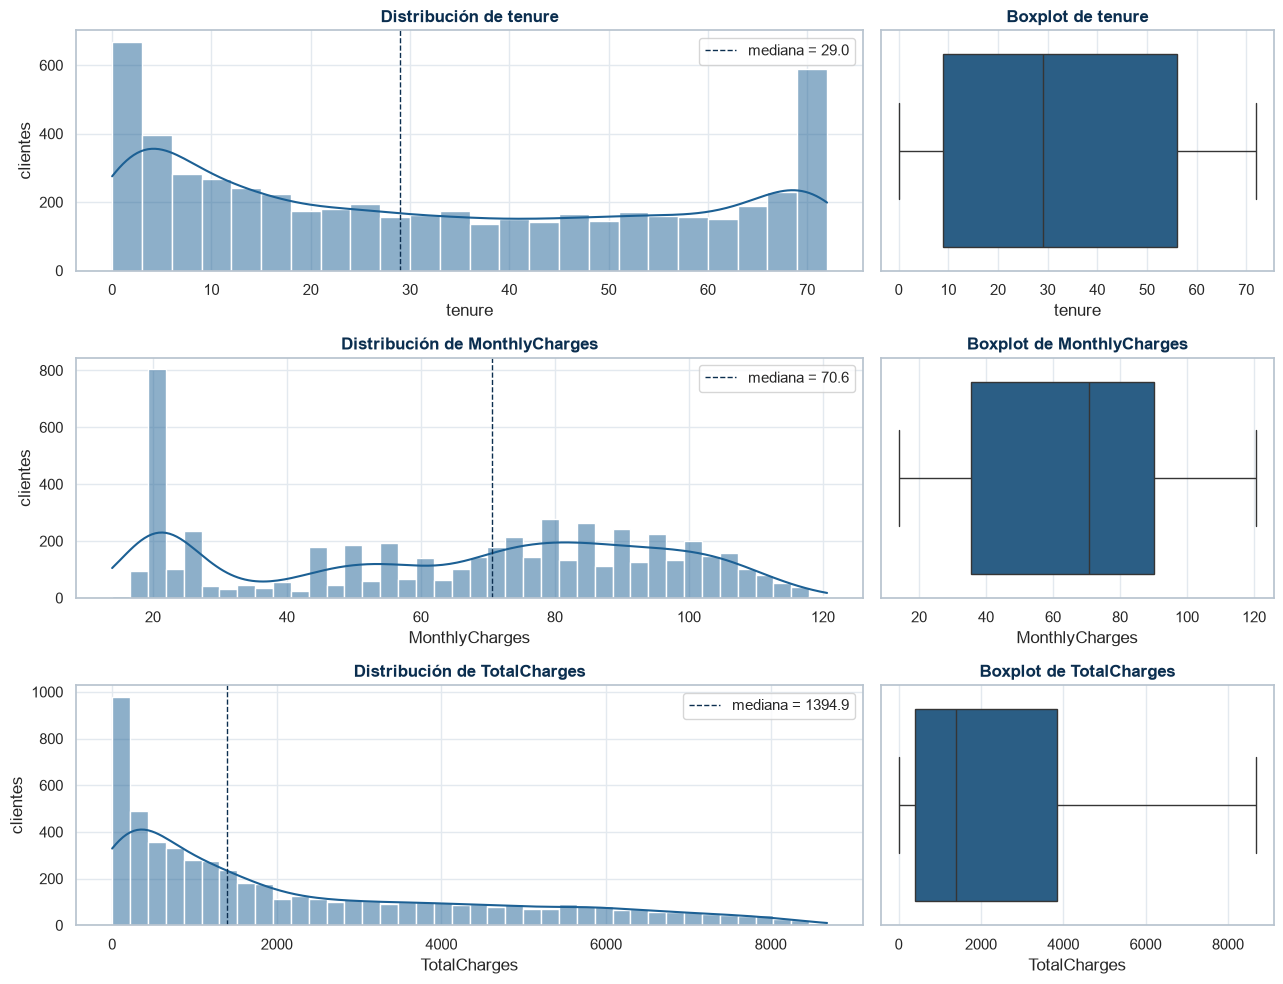

In [24]:
filas = []   # una fila por variable
for col in COLS_NUM:                                           # posición, dispersión, forma y outliers
    x = train[col].dropna()   # valores observados
    q1, q3 = x.quantile([0.25, 0.75])                          # cuartiles
    filas.append({'variable': col, 'media': x.mean(), 'Q1': q1, 'mediana': x.median(), 'Q3': q3, 'desvío': x.std(), 'mín': x.min(),   # medidas de la variable
                  'máx': x.max(), 'asimetría': x.skew(), 'curtosis': x.kurt(),   # máximo y forma
                  'outliers 1,5·IQR': int(((x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))).sum())})   # fuera de los bigotes
display(pd.DataFrame(filas).set_index('variable').round(2))   # muestro la tabla
print('Valores de tenure más frecuentes:', train['tenure'].value_counts().head(3).to_dict())   # picos del histograma

fig, axes = plt.subplots(3, 2, figsize=(13, 10), gridspec_kw={'width_ratios': [2, 1]})   # 3 filas x 2 columnas
for i, col in enumerate(COLS_NUM):                             # una fila de paneles por variable
    bins = np.arange(0, 75, 3) if col == 'tenure' else 40      # bins de 3 meses para una variable entera
    sns.histplot(train[col], bins=bins, kde=True, color=AZUL_UTN, ax=axes[i, 0])   # histograma y densidad
    mediana = train[col].median()                              # mediana para marcarla
    axes[i, 0].axvline(mediana, color=AZUL_OSCURO, ls='--', lw=1, label=f'mediana = {mediana:.1f}')   # marco la mediana
    axes[i, 0].set_ylabel('clientes')                          # eje y
    axes[i, 0].legend()                                        # referencia de la mediana
    axes[i, 0].set_title(f'Distribución de {col}')             # título del histograma
    sns.boxplot(x=train[col], color=AZUL_UTN, ax=axes[i, 1])  # boxplot horizontal
    axes[i, 1].set_title(f'Boxplot de {col}')                  # título del boxplot
plt.tight_layout()                                             # acomodo los paneles
guardar_figura('numericas_distribucion')                       # guardo el PNG
plt.show()                                                     # muestro la figura

- `tenure` tiene forma de U: 477 clientes con un solo mes y 278 con 72, el máximo posible. El pico en 72 sugiere un registro truncado en 6 años, de modo que para el modelo "72" significa "72 o más".
- `MonthlyCharges` es bimodal: un grupo cerca de 20 (solo teléfono, sin internet) y otro entre 70 y 105 (con internet, sobre todo fibra). Por eso la mediana (70,6) supera a la media (64,9).
- `TotalCharges` tiene asimetría positiva (0,95): la media (2.299) supera en dos tercios a la mediana (1.395), como corresponde a un monto acumulado.

Ninguna tiene outliers por el criterio de 1,5·IQR, y las tres son más aplanadas que una normal (curtosis negativa).

> **Decisiones 9 y 10:** no eliminar outliers. Escalar las numéricas con `StandardScaler` dentro del pipeline y probar `log1p(TotalCharges)` como transformación opcional, que se adopta solo si mejora la validación cruzada.
>
> **Justificación:** el criterio de 1,5·IQR no marca ningún valor y todos son posibles para el negocio; los cargos de 14 a 121 que se ven en train incluyen los deducidos por R6. Las escalas son muy distintas (meses, decenas y miles), y KNN, SVM, la regresión logística, las redes neuronales y el PCA dependen de la escala; los árboles no. Elegimos la estandarización frente al min-max porque no hay outliers que distorsionen el desvío. El PCA requiere centrar las variables; llevarlas además a desvío 1 es una elección, que tomamos para que ninguna numérica domine las componentes solo por su unidad de medida (Géron, 2022, cap. 2, *Feature Scaling and Transformation*; James et al., 2023, sec. 12.2.4). El logaritmo puede acercar `TotalCharges` a una forma más simétrica, pero si eso ayuda al modelo lo decide la validación.

## 7.2 Categóricas

Usamos `train_orig`, el train antes de las reglas (sección 6.5). Buscamos categorías muy raras y variables casi constantes. Una categoría con muy pocos clientes produce una dummy que casi siempre vale 0, con tasas de churn inestables, y una variable casi constante no ayuda a distinguir clientes.

La celda imprime la categoría menos frecuente de todo el conjunto y grafica un panel por variable, con el porcentaje de clientes en cada categoría. El título de cada panel indica el porcentaje de faltantes, y las barras se calculan sobre los clientes que tienen el dato. Si la categoría más chica supera largamente el 1% o 2%, no hace falta agrupar categorías.

Clientes de train: 5634 | categoría menos frecuente: MultipleLines = No phone service (9.9%)


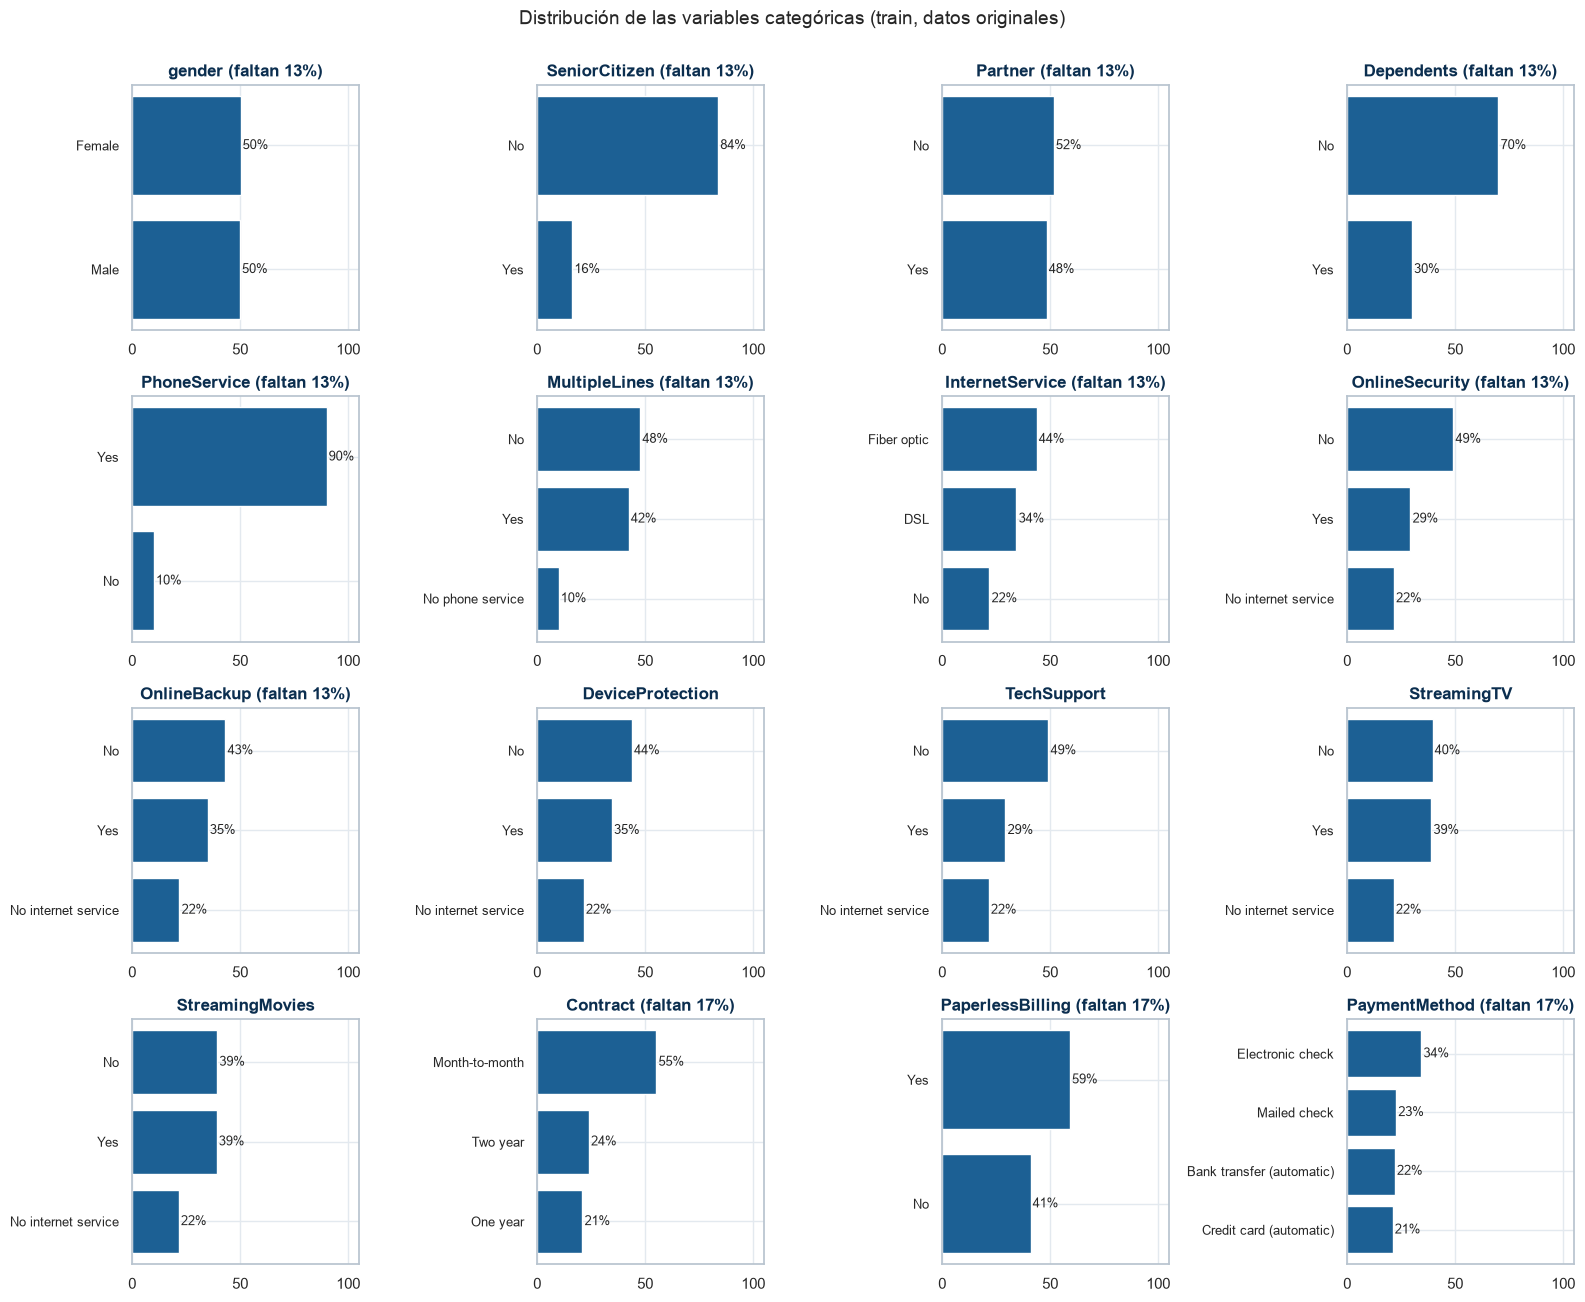

In [25]:
menos_frecuente = {c: train_orig[c].value_counts(normalize=True).min() * 100 for c in COLS_CAT}   # % de la categoría más chica de cada variable
var_min = min(menos_frecuente, key=menos_frecuente.get)                                           # variable con la categoría más rara
print(f'Clientes de train: {len(train_orig)} | categoría menos frecuente: {var_min} = '            # verificación de categorías raras
      f'{train_orig[var_min].value_counts(normalize=True).idxmin()} ({menos_frecuente[var_min]:.1f}%)')   # nombre y porcentaje

fig, axes = plt.subplots(4, 4, figsize=(16, 13))               # una grilla para las 16 categóricas
for ax, col in zip(axes.flat, COLS_CAT):   # un panel por categórica
    proporciones = train_orig[col].value_counts(normalize=True).sort_values() * 100   # % por categoría
    ax.barh(proporciones.index.astype(str), proporciones.values, color=AZUL_UTN)   # barras horizontales
    for j, v in enumerate(proporciones.values):                # % al lado de cada barra
        ax.text(v + 1, j, f'{v:.0f}%', va='center', fontsize=9)   # % al lado de la barra
    ax.set_xlim(0, 105)   # mismo eje en todos los paneles
    pct_falta = train_orig[col].isna().mean() * 100            # % de clientes sin el dato
    ax.set_title(f'{col} (faltan {pct_falta:.0f}%)' if pct_falta > 0 else col)   # nombre y % faltante
    ax.tick_params(axis='y', labelsize=9)   # letra chica para las categorías
plt.suptitle('Distribución de las variables categóricas (train, datos originales)', y=1.0, fontsize=14)   # título general
plt.tight_layout()   # acomodo los paneles
guardar_figura('categoricas_distribucion')                     # guardo el PNG
plt.show()   # muestro la figura

`gender` está repartido 50/50; el 16% de los clientes es jubilado y el 30% tiene dependientes. El 90% tiene teléfono. En internet, 44% tiene fibra, 34% DSL y 22% no tiene. Seguridad y soporte los contrata el 29%, y el streaming, casi el 40%. El 55% tiene contrato mes a mes, el 59% factura electrónica, y el medio de pago más usado es el cheque electrónico (34%). Las categorías menos frecuentes (`PhoneService = No` y `MultipleLines = No phone service`, los mismos clientes) rondan el 10%, así que no hay categorías raras ni variables casi constantes.

# 8. Análisis bivariado: cada variable contra el churn (train)

Como en la sección 7.1, usamos `train`, el conjunto de entrenamiento con las reglas aplicadas. Buscamos qué variables se asocian con la baja y con qué intensidad, para saber qué información tiene que aprovechar el modelo.

## 8.1 Categóricas

Calculamos la tasa de churn de cada categoría (VanderPlas, 2016, cap. 3, *Aggregation and Grouping*) con su intervalo de confianza del 95% por aproximación normal, adecuada con cientos de clientes por categoría. Resumimos cada variable con la V de Cramér (Cramér, 1946), que va de 0 a 1 y sale del chi-cuadrado; con una binaria como el churn leemos 0,1, 0,3 y 0,5 como asociación débil, moderada y fuerte (Cohen, 1988). Con más de 5.000 clientes casi cualquier diferencia es significativa, así que para ordenar las variables usamos la V y no el p-valor.

La primera celda calcula la tasa global de train, que sirve de referencia en los gráficos, y define `cramers_v`. El chi-cuadrado crece con el tamaño de la muestra, y la V lo corrige: `V = √(χ² / (n · (k - 1)))`, con `k` la menor cantidad entre filas y columnas de la tabla. Así queda entre 0 (independencia) y 1 (una variable determina a la otra). Esperamos una tasa global de 26,5%, la misma que fijó la estratificación.

In [26]:
TASA_GLOBAL = train['churn_num'].mean()                        # tasa de churn de train
print(f'Tasa de churn de train: {TASA_GLOBAL:.1%} ({len(train)} clientes)')   # referencia de los gráficos


def cramers_v(x, y):   # V de Cramér entre dos categóricas
    # de 0 a 1; ignora NaN
    tabla = pd.crosstab(x, y)                                  # tabla de contingencia
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]  # chi-cuadrado sin corrección de Yates
    return np.sqrt(chi2 / (tabla.to_numpy().sum() * (min(tabla.shape) - 1)))   # fórmula de Cramér

Tasa de churn de train: 26.5% (5634 clientes)


El gráfico siguiente tiene un panel por categórica. Cada barra es la tasa de churn de una categoría con su intervalo del 95%, `p ± 1,96 · √(p(1 - p) / n)`, y la línea punteada marca la tasa global. Una categoría cuya barra queda lejos de la línea, con un intervalo que no la toca, tiene más o menos bajas que el promedio. El título de cada panel trae la V de la variable. Si una variable no se asocia con el churn, todas sus barras quedan cerca de la línea.

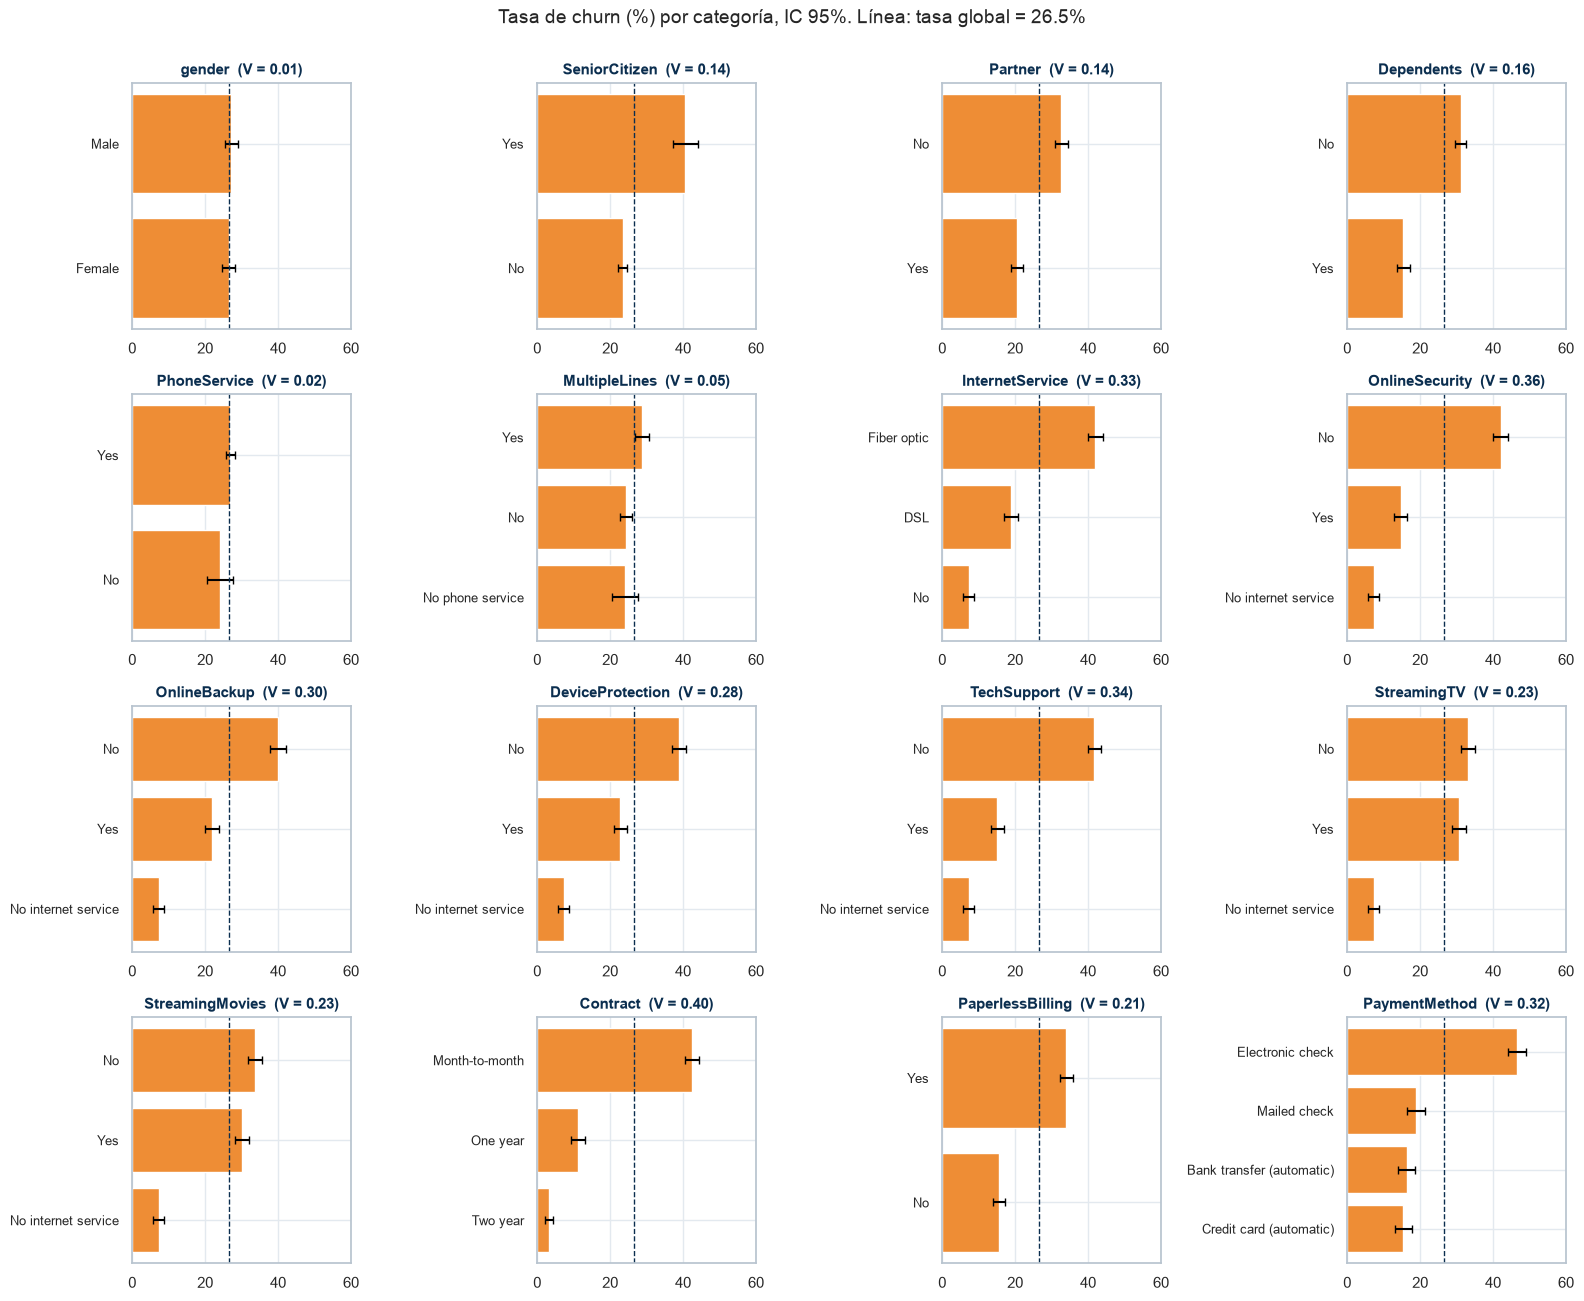

In [27]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))   # una grilla para las 16 categóricas
for ax, col in zip(axes.flat, COLS_CAT):                       # tasa de churn por categoría con IC 95%
    tasa_n = train.groupby(col)['churn_num'].agg(['mean', 'count']).sort_values('mean')   # tasa y n por categoría
    ic = 1.96 * np.sqrt(tasa_n['mean'] * (1 - tasa_n['mean']) / tasa_n['count'])   # medio ancho del IC 95%
    ax.barh(tasa_n.index.astype(str), tasa_n['mean'] * 100, xerr=ic * 100, color=NARANJA, capsize=3)   # tasa por categoría con su IC
    ax.axvline(TASA_GLOBAL * 100, color=AZUL_OSCURO, ls='--', lw=1)   # tasa global
    ax.set_title(f'{col}  (V = {cramers_v(train[col], train[TARGET]):.2f})', fontsize=11)   # nombre y V de Cramér
    ax.set_xlim(0, 60)   # mismo eje en todos los paneles
    ax.tick_params(axis='y', labelsize=9)   # letra chica para las categorías
plt.suptitle(f'Tasa de churn (%) por categoría, IC 95%. Línea: tasa global = {TASA_GLOBAL * 100:.1f}%', y=1.0, fontsize=14)   # título general
plt.tight_layout()   # acomodo los paneles
guardar_figura('churn_por_categoria')                          # guardo el PNG
plt.show()   # muestro la figura

Después resumimos cada variable en un número. Para cada categórica calculamos el chi-cuadrado contra el churn, su p-valor, la V de Cramér y la menor frecuencia esperada de la tabla, que controla el supuesto del test (al menos 5 clientes esperados por celda). El gráfico ordena las variables por V y pinta de gris las que no son significativas; la tabla muestra los valores exactos.

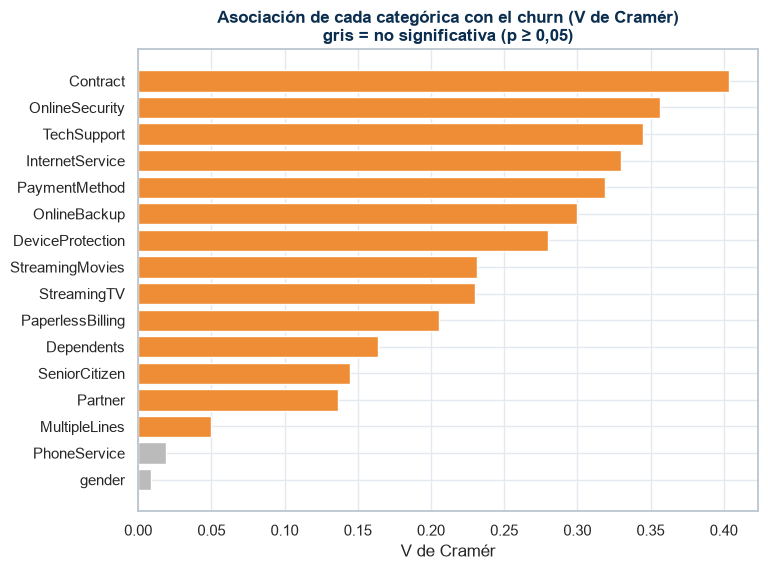

,V de Cramér,p-valor,mín. frecuencia esperada
variable,,,
Contract,0.403,3.18e-166,260
OnlineSecurity,0.356,9.28e-140,315
TechSupport,0.345,2.79e-146,322
InternetService,0.330,2.31e-121,314
PaymentMethod,0.319,3.82e-103,267
OnlineBackup,0.300,3.47e-99,315
DeviceProtection,0.280,1.50e-96,322
StreamingMovies,0.232,2.13e-66,322
StreamingTV,0.230,1.17e-65,322


In [28]:
filas = []   # una fila por variable
for col in COLS_CAT:                                           # chi-cuadrado, V y supuesto de frecuencias esperadas
    tabla = pd.crosstab(train[col], train[TARGET])   # tabla de contingencia contra churn
    chi2, p, gl, esperadas = stats.chi2_contingency(tabla, correction=False)   # chi-cuadrado sin corrección de Yates
    filas.append({'variable': col, 'V de Cramér': cramers_v(train[col], train[TARGET]), 'p-valor': p,   # guardo V, p-valor y supuesto
                  'mín. frecuencia esperada': esperadas.min()})   # supuesto del chi-cuadrado
asociacion = pd.DataFrame(filas).set_index('variable').sort_values('V de Cramér', ascending=False)   # ordenada por V

fig, ax = plt.subplots(figsize=(8, 6))                         # figura mediana
colores = [NARANJA if p < 0.05 else '#BBBBBB' for p in asociacion['p-valor']]   # gris si no es significativa
ax.barh(asociacion.index[::-1], asociacion['V de Cramér'][::-1], color=colores[::-1])   # de mayor a menor
ax.set_title('Asociación de cada categórica con el churn (V de Cramér)\ngris = no significativa (p ≥ 0,05)')   # título
ax.set_xlabel('V de Cramér')                                   # eje x
guardar_figura('cramers_v_churn')                              # guardo el PNG
plt.show()                                                     # muestro la figura
asociacion.style.format({'V de Cramér': '{:.3f}', 'p-valor': '{:.2e}', 'mín. frecuencia esperada': '{:.0f}'})   # tabla con formato

La frecuencia esperada mínima es 143, así que se cumple el supuesto del chi-cuadrado (al menos 5 por celda).

| Variable | V | Qué muestra |
|---|---|---|
| `Contract` | 0,40 | Mes a mes 42%, un año 11%, dos años 3% |
| `OnlineSecurity` y `TechSupport` | 0,36 y 0,35 | Sin el servicio 42%, con el servicio 15% |
| `InternetService` | 0,33 | Fibra 42%, DSL 19%, sin internet 7% |
| `PaymentMethod` | 0,32 | Cheque electrónico 47%; los otros tres medios, de 15% a 19% |
| `OnlineBackup` y `DeviceProtection` | 0,30 y 0,28 | Sin el servicio 40% y 39%; con él, 22% y 23% |
| `StreamingTV` y `StreamingMovies` | 0,23 | Yes 30% contra No 33%: la asociación viene de "No internet service" |
| `PaperlessBilling` | 0,21 | Factura electrónica 34%, en papel 16% |
| `Dependents`, `SeniorCitizen`, `Partner` | 0,14 a 0,16 | Jubilados 41% contra 23%; sin dependientes 31% contra 15%; sin pareja 33% contra 21% |
| `MultipleLines` | 0,05 | 29% contra 24%: significativa pero chica |
| `PhoneService` y `gender` | 0,02 y 0,01 | Sin asociación (p = 0,15 y 0,55) |

En "No internet service" el churn es 7% en los 6 adicionales, porque son los mismos clientes. Los servicios de protección van con menos bajas y el streaming casi no cambia la tasa. Con estos datos no podemos distinguir si esos servicios retienen al cliente o si los contratan clientes que igual se iban a quedar (sección 9.4).

> **Decisión 17:** evaluar por validación cruzada, en el notebook de machine learning, si conviene eliminar `gender` y `PhoneService`.
>
> **Justificación:** ninguna de las dos se asocia con el churn, y `PhoneService` además es redundante con `MultipleLines` (sección 9.2). Una variable sin asociación marginal podría aportar en combinación con otras, así que el gráfico no alcanza para descartarla. Una logística con penalización L1 puede llevar sus coeficientes a cero, mientras que la L2 solo los achica (James et al., 2023, sec. 6.2.2); la decisión queda en manos de la validación.

## 8.2 Numéricas

Comparamos las distribuciones de los que se quedan y los que se van con densidades normalizadas por grupo, para que el desbalance no achique la curva de los que se van. Cuantificamos con la diferencia de medianas, la correlación de Pearson con `churn_num` y el test de Mann-Whitney (Mann y Whitney, 1947). Como tamaño de efecto usamos la correlación biserial por rangos, positiva si la variable es mayor en los que se van.

La primera celda grafica, para cada numérica, la densidad de cada grupo arriba y su boxplot abajo. Con `common_norm=False` cada curva integra 1 dentro de su grupo, así que comparamos formas y no tamaños. Si una variable se asocia con el churn, las dos curvas se separan.

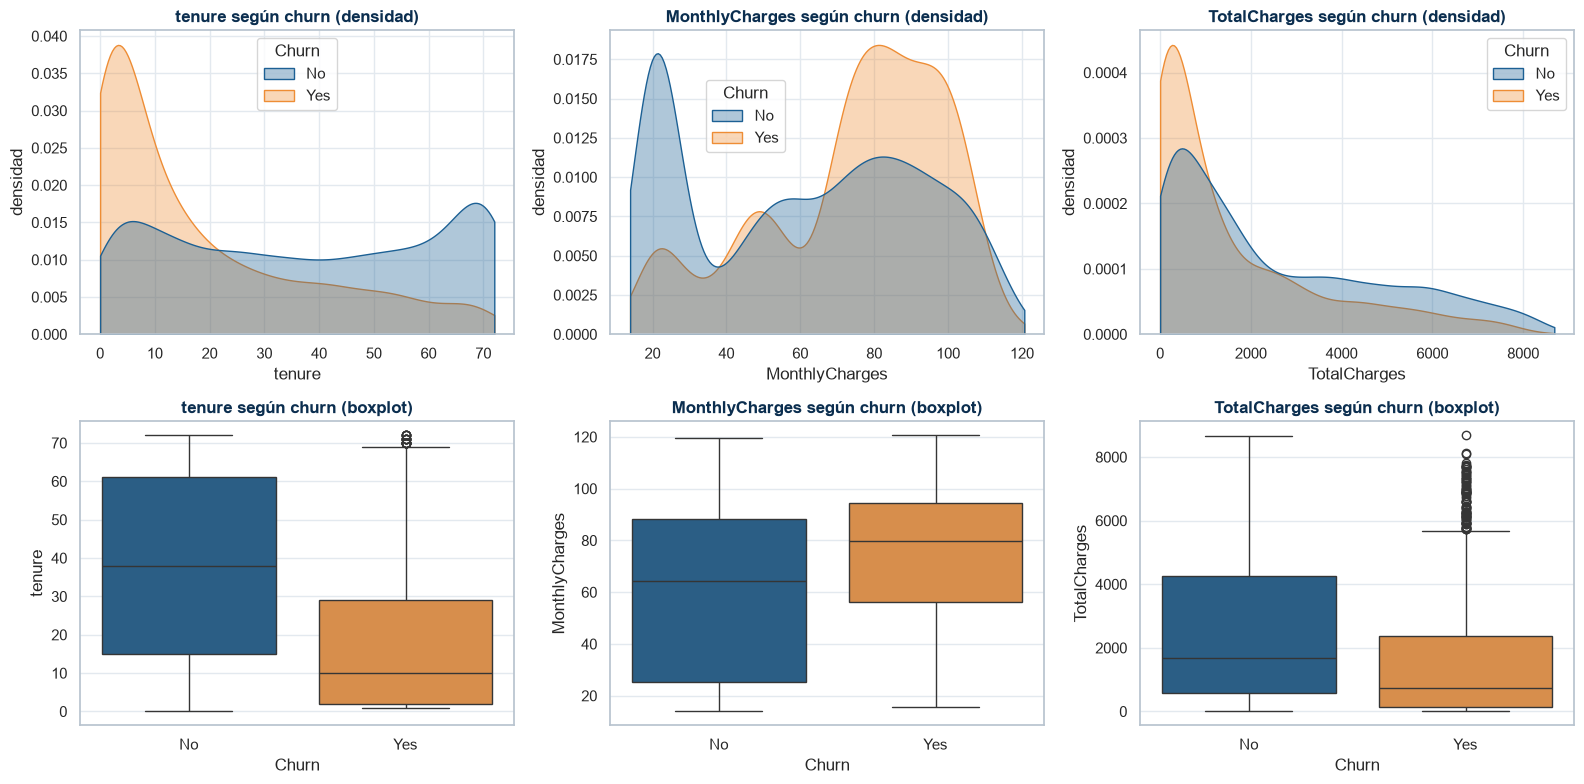

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))                # fila 1: densidades, fila 2: boxplots
LEYENDAS = {'tenure': 'upper center', 'MonthlyCharges': (0.22, 0.6), 'TotalCharges': 'upper right'}   # zona libre de cada panel
for i, col in enumerate(COLS_NUM):                             # una columna de paneles por variable
    rango = (train[col].min(), train[col].max())               # límites reales de la variable
    sns.kdeplot(data=train, x=col, hue=TARGET, hue_order=['No', 'Yes'], palette=COLORES_CHURN,   # densidad de cada grupo
                common_norm=False, fill=True, alpha=0.35, clip=rango, ax=axes[0, i])   # una densidad por grupo
    axes[0, i].set_title(f'{col} según churn (densidad)')      # título
    axes[0, i].set_ylabel('densidad')                          # eje y
    sns.move_legend(axes[0, i], LEYENDAS[col])                 # leyenda donde no tapa las curvas
    sns.boxplot(data=train, x=TARGET, y=col, hue=TARGET, order=['No', 'Yes'], palette=COLORES_CHURN,   # boxplot de cada grupo
                legend=False, ax=axes[1, i])                   # boxplot por grupo
    axes[1, i].set_title(f'{col} según churn (boxplot)')       # título
plt.tight_layout()                                             # acomodo los paneles
guardar_figura('numericas_vs_churn')                           # guardo el PNG
plt.show()                                                     # muestro la figura

La tabla pone en números lo que muestran los gráficos. Para cada numérica informa la mediana de cada grupo y la correlación de Pearson con `churn_num`, que con una variable 0/1 equivale a la correlación punto-biserial. Agrega el p-valor de Mann-Whitney y la correlación biserial por rangos, `r = 2U / (n₁ · n₀) - 1`. Esa `r` va de -1 a 1 y vale 0 cuando un cliente que se va tiene la misma probabilidad de estar por encima o por debajo de uno que se queda. A diferencia del p-valor, no depende del tamaño de la muestra.

In [30]:
filas = []   # una fila por variable
for col in COLS_NUM:   # recorro las numéricas
    se_va, se_queda = train.loc[train['churn_num'] == 1, col].dropna(), train.loc[train['churn_num'] == 0, col].dropna()   # valores de cada grupo
    u, p = stats.mannwhitneyu(se_va, se_queda)                 # test de Mann-Whitney
    obs = train[[col, 'churn_num']].dropna()                   # pares completos para Pearson
    filas.append({'variable': col, 'mediana se va': se_va.median(), 'mediana se queda': se_queda.median(),   # medianas, Pearson y Mann-Whitney
                  'Pearson con churn': obs[col].corr(obs['churn_num']), 'p-valor Mann-Whitney': p,   # Pearson y p-valor
                  'r biserial por rangos': 2 * u / (len(se_va) * len(se_queda)) - 1})   # tamaño del efecto
display(pd.DataFrame(filas).set_index('variable').style.format(   # muestro la tabla con formato
    {'mediana se va': '{:.1f}', 'mediana se queda': '{:.1f}', 'Pearson con churn': '{:.3f}',   # decimales por columna
     'p-valor Mann-Whitney': '{:.1e}', 'r biserial por rangos': '{:.3f}'}))   # p-valor en notación científica

,mediana se va,mediana se queda,Pearson con churn,p-valor Mann-Whitney,r biserial por rangos
variable,,,,,
tenure,10.0,38.0,-0.348,6.6e-160,-0.474
MonthlyCharges,79.8,64.4,0.196,5.6e-44,0.245
TotalCharges,740.3,1686.2,-0.194,1.4e-62,-0.291


`tenure` es la que más separa a los grupos, así que la cortamos en cinco tramos: hasta 6 meses, 7 a 12, 13 a 24, 25 a 48 y 49 a 72. Los cortes son un semestre, un año y dos años, coherentes con la duración de los contratos anual y bianual, y después cuatro años completos hasta el máximo de 72 meses. Para cada tramo calculamos la tasa de churn con su intervalo del 95%. Los tramos muestran la forma de la relación sin suponer que sea lineal. La variable `tramos` se reutiliza en la sección 9.3. Esperamos tasas que bajan con la antigüedad.

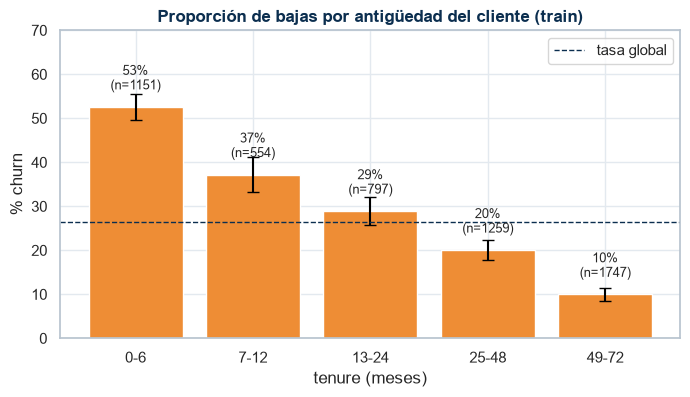

In [31]:
tramos = pd.cut(train['tenure'], bins=[-1, 6, 12, 24, 48, 72], labels=['0-6', '7-12', '13-24', '25-48', '49-72'])   # tramos de antigüedad
por_tramo = train.groupby(tramos, observed=True)['churn_num'].agg(['mean', 'count'])   # tasa y n por tramo
ic = 1.96 * np.sqrt(por_tramo['mean'] * (1 - por_tramo['mean']) / por_tramo['count'])   # IC 95% de cada tasa
fig, ax = plt.subplots(figsize=(8, 4))                                 # figura mediana
ax.bar(por_tramo.index.astype(str), por_tramo['mean'] * 100, yerr=ic * 100, color=NARANJA, capsize=4)   # tasa por tramo con su IC
ax.axhline(TASA_GLOBAL * 100, color=AZUL_OSCURO, ls='--', lw=1, label='tasa global')   # referencia
for pos, (tasa_tramo, n_tramo) in enumerate(zip(por_tramo['mean'], por_tramo['count'])):   # tasa y n arriba
    ax.text(pos, tasa_tramo * 100 + 4, f'{tasa_tramo * 100:.0f}%\n(n={n_tramo})', ha='center', fontsize=9)   # tasa y n arriba de la barra
ax.set_ylim(0, 70)                                                     # rango del eje y
ax.set_title('Proporción de bajas por antigüedad del cliente (train)')  # título
ax.set_xlabel('tenure (meses)')                                        # eje x
ax.set_ylabel('% churn')                                               # eje y
ax.legend()                                                            # leyenda
guardar_figura('churn_por_tenure')                                     # guardo el PNG
plt.show()                                                             # muestro la figura

- `tenure` es la numérica más asociada (Pearson -0,35; biserial por rangos -0,47). Los que se van tienen una mediana de 10 meses contra 38. Por tramos, la proporción de bajas cae de forma monótona: 53% hasta 6 meses, 37%, 29%, 20% y 10% después de 4 años. La caída es fuerte al principio y después se aplana, una relación no lineal.
- `MonthlyCharges`: los que se van pagan más (mediana 79,8 contra 64,4; Pearson 0,20). Las bajas se concentran entre 70 y 105 (fibra) y casi no aparecen entre los que pagan unos 20.
- `TotalCharges`: los que se van acumularon menos (740 contra 1.686; Pearson -0,19), sobre todo porque llevan menos tiempo.

Los tres tests de Mann-Whitney dan p < 10⁻⁴³. La lectura de `tenure` tiene un límite: el dataset es una foto sin ventana temporal, y la antigüedad de los clientes activos está censurada, porque todavía no sabemos cuándo se van a ir. La tasa de un tramo es la proporción de clientes con esa antigüedad que figura como baja, no la probabilidad de irse en ese momento (James et al., 2023, cap. 11).

## 8.3 Ingresos en riesgo y costo de los errores

### Impacto en ingresos

Un cliente que se va no pesa lo mismo que otro: el que paga más se lleva más facturación. La celda toma los clientes de train con cargo mensual conocido y compara el porcentaje de clientes que se van con el porcentaje de la facturación mensual que representan. También calcula el cargo promedio de cada grupo, que es la base de la pérdida de la decisión 18. Como los que se van pagan más (sección 8.2), esperamos que pesen más en facturación que en cantidad.

Clientes que se van: 26.6% de los que tienen cargo conocido | facturación mensual que representan: 30.7%
Cargo mensual promedio: {'No': 61.4, 'Yes': 74.7} | un año de cargo de un cliente que se va: 897


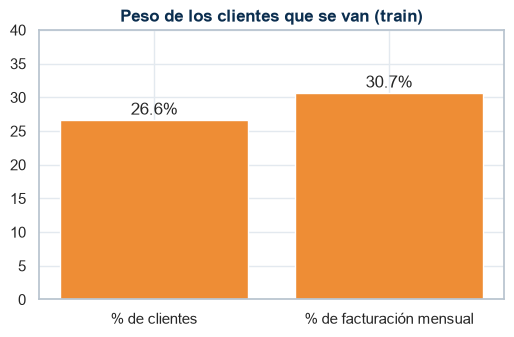

In [32]:
con_cargo = train.dropna(subset=['MonthlyCharges'])            # clientes con cargo mensual conocido
pct_clientes = con_cargo['churn_num'].mean() * 100             # % de clientes que se van
pct_ingresos = con_cargo.loc[con_cargo['churn_num'] == 1, 'MonthlyCharges'].sum() / con_cargo['MonthlyCharges'].sum() * 100   # % de la facturación que se va
cargo_medio = con_cargo.groupby(TARGET)['MonthlyCharges'].mean()   # cargo medio de cada grupo
print(f'Clientes que se van: {pct_clientes:.1f}% de los que tienen cargo conocido | facturación mensual que representan: {pct_ingresos:.1f}%')   # peso en clientes y en facturación
print('Cargo mensual promedio:', cargo_medio.round(1).to_dict(), f'| un año de cargo de un cliente que se va: {12 * cargo_medio["Yes"]:.0f}')   # base de la pérdida

fig, ax = plt.subplots(figsize=(6, 3.5))                                # figura chica
ax.bar(['% de clientes', '% de facturación mensual'], [pct_clientes, pct_ingresos], color=NARANJA)   # dos barras: clientes y facturación
for pos, valor in enumerate([pct_clientes, pct_ingresos]):              # anoto el valor arriba de cada barra
    ax.text(pos, valor + 0.8, f'{valor:.1f}%', ha='center')   # valor arriba de la barra
ax.set_ylim(0, 40)                                                      # rango del eje y
ax.set_title('Peso de los clientes que se van (train)')                 # título
guardar_figura('ingresos_en_riesgo')                                    # guardo el PNG
plt.show()                                                              # muestro la figura

Los que se van son el 26,6% de los clientes de train con cargo conocido, pero el 30,7% de la facturación mensual, porque pagan 74,7 por mes contra 61,4. En valor acumulado ocurre lo contrario, porque llevan menos tiempo; el argumento para el negocio es sobre ingreso mensual.

### Costo de los errores

La matriz de costos de la decisión 13 necesita dos montos que el dataset no trae: cuánto pierde la empresa cuando se va un cliente que no detectamos y cuánto cuesta la oferta de retención. Los fijamos con un criterio de negocio explícito y medimos cuánto depende la decisión de ellos.

**Pérdida por cliente que se va: 897.** La medimos como la facturación que la empresa deja de cobrar, en la línea del valor de vida del cliente (Gupta et al., 2006), y la calculamos como cargo mensual por horizonte.

- El cargo es la media de los que se van en train, 74,7. Usamos la media y no la mediana porque buscamos la pérdida total esperada, que es la media por la cantidad de bajas.
- El horizonte es de 12 meses. La acción de retención que sugiere este análisis es pasar al cliente a un contrato anual, porque el mes a mes concentra las bajas (42%) y el anual baja al 11%. Si la retención funciona, lo que la empresa asegura es un año de facturación. Más allá de ese año no sabemos cuánto seguiría el cliente: `tenure` está censurada y estimarlo requeriría un modelo de supervivencia (James et al., 2023, cap. 11). Un horizonte más largo sumaría meses de facturación que no podemos respaldar con estos datos.

**Costo de la oferta: 120.** La planteamos como un descuento a cambio de firmar ese contrato anual: 120 es el 13% del año, unos 1,6 meses de cargo. Tiene que ser chico frente a lo que protege, porque también se paga a cada cliente contactado que se iba a quedar igual (los falsos positivos). Y tiene que ser un beneficio concreto para quien se compromete por un año: la empresa resigna 120 para conservar 897. Expresarlo como porcentaje del año permite reemplazarlo por el descuento que defina el área comercial; la tabla prueba 10% y 20%.

**Lo que el escenario base no descuenta.** El 897 es facturación y no ganancia, porque el margen no está en los datos. Y no todo cliente que recibe la oferta la acepta. Las dos cosas achican lo que se recupera con cada acierto. Si `f` es la parte de la pérdida que se recupera, contactar a un cliente con probabilidad `p` de irse cuesta `120 + p(1 - f)·897` y no contactarlo cuesta `p·897`, así que conviene contactarlo cuando `p > 120 / (f·897)` (Murphy, 2022, sec. 5.1.2.2). La aceptación y el margen entran en un solo parámetro, como en la evaluación de modelos de churn por beneficio de Verbraken et al. (2013), y la tabla lo recorre.

La celda calcula el escenario base y la tabla de sensibilidad, donde cada valor es el umbral óptimo `oferta / (f · pérdida)`: las filas recorren `f` y las columnas el costo de la oferta. Esperamos un umbral base cercano a 0,13, que sube cuando la oferta es más cara o se recupera menos.

In [33]:
perdida = 12 * cargo_medio['Yes']                              # pérdida por cliente que se va: 12 meses de su cargo medio
oferta = 120                                                   # costo de la oferta de retención (supuesto)
print(f'Pérdida: {perdida:.1f} | oferta: {oferta} ({oferta / perdida:.1%} del año, '   # escenario base
      f'{oferta / cargo_medio["Yes"]:.1f} meses de cargo) | umbral base: {oferta / perdida:.3f}')   # meses de cargo y umbral
fracciones = [1.0, 0.75, 0.5, 0.25]                             # parte de la pérdida que se recupera (aceptación x margen)
ofertas = {'10% del año': 0.10 * perdida, f'{oferta} ({oferta / perdida:.0%})': oferta, '20% del año': 0.20 * perdida}   # costos posibles de la oferta
umbrales = pd.DataFrame({nombre: [costo / (f * perdida) for f in fracciones] for nombre, costo in ofertas.items()},   # umbral de cada combinación
                        index=[f'{f:.0%}' for f in fracciones])   # umbral óptimo de cada escenario
umbrales.index.name = 'se recupera'                            # nombre de las filas
umbrales.columns.name = 'costo de la oferta'                   # nombre de las columnas
umbrales.round(2)                                              # muestro la tabla

Pérdida: 896.6 | oferta: 120 (13.4% del año, 1.6 meses de cargo) | umbral base: 0.134


costo de la oferta,10% del año,120 (13%),20% del año
se recupera,,,
100%,0.100,0.130,0.200
75%,0.130,0.180,0.270
50%,0.200,0.270,0.400
25%,0.400,0.540,0.800


En el escenario base el umbral es 0,134: conviene ofrecer la retención a todo cliente con probabilidad de irse mayor al 13,4%. Si se recupera la mitad, por aceptación o por margen, sube a 0,27, y con una oferta del 20% del año y un 25% recuperado llega a 0,80, donde la oferta casi deja de convenir. Mientras la oferta cueste mucho menos que lo que se recupera, el umbral queda muy por debajo del 0,5 de `predict`: a la empresa le sale más barato ofrecer de más que perder un cliente.

> **Decisión 18:** usar como escenario base una pérdida de 897 por cliente que se va (12 meses del cargo medio de los que se van, en train) y una oferta de 120 (13% de ese año), con umbral teórico 0,134. En el notebook de machine learning el umbral se elige con validación cruzada en train para ese escenario, y se informa cómo cambian el umbral y el costo total en los escenarios de la tabla.
>
> **Justificación:** el costo de un error no está en los datos, así que cualquier monto es un supuesto; lo que lo vuelve defendible es que cada parte tenga un motivo. El cargo sale de los clientes que se van en este dataset. El horizonte es el del contrato anual que propone la retención, y la censura de `tenure` no permite extenderlo (James et al., 2023, cap. 11). La oferta es un descuento acotado sobre ese año, que también se paga en los falsos positivos. Como el umbral depende solo del cociente entre la oferta y lo que se recupera (Murphy, 2022, sec. 5.1.2.2), la tabla de sensibilidad cubre a la vez el margen desconocido y la aceptación de la oferta (Verbraken et al., 2013).

# 9. Análisis multivariado (train)

El análisis bivariado mira cada variable por separado. Ahora buscamos relaciones entre predictoras: redundancias que afectan a los modelos lineales y al PCA, y combinaciones de variables que cambian la tasa de churn más de lo que sugiere cada una sola.

## 9.1 Correlación entre numéricas

Calculamos Pearson, que mide relación lineal, y Spearman (Spearman, 1904), que mide relación monótona porque se calcula sobre los rangos. Los acompañamos con gráficos de dispersión, porque un coeficiente solo puede ocultar la forma de la relación.

La primera celda muestra las dos matrices de correlación lado a lado, con el valor de cada par en la celda. Esperamos una correlación alta entre `TotalCharges` y `tenure`, porque el total acumulado crece con los meses.

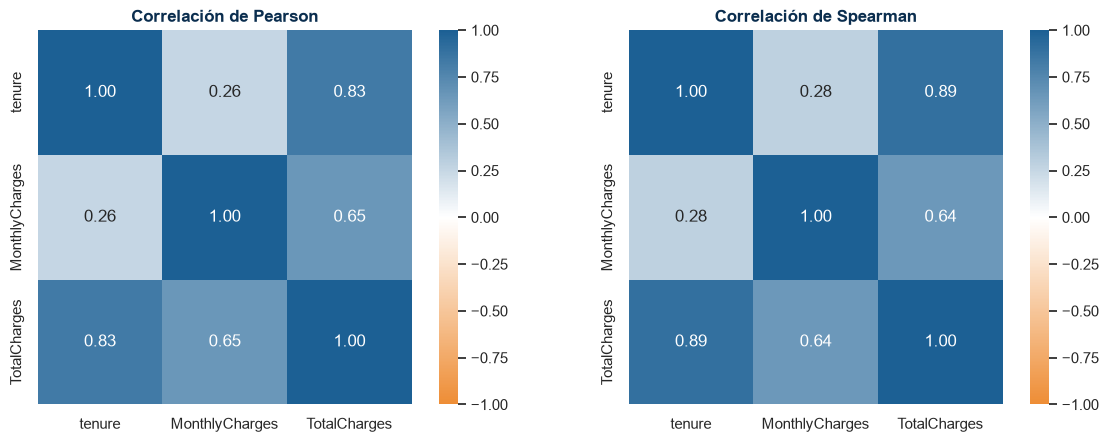

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))                        # dos heatmaps lado a lado
for ax, metodo in zip(axes, ['pearson', 'spearman']):                    # un heatmap por método
    sns.heatmap(train[COLS_NUM].corr(method=metodo), annot=True, fmt='.2f', cmap=CMAP_DIVERGENTE,   # matriz de correlación
                vmin=-1, vmax=1, square=True, ax=ax)                     # matriz con el valor en cada celda
    ax.set_title(f'Correlación de {metodo.capitalize()}')                # título
plt.tight_layout()                                                       # acomodo los paneles
guardar_figura('correlacion_numericas')                                  # guardo el PNG
plt.show()                                                               # muestro la figura

La segunda celda grafica `tenure` contra cada monto, con los puntos coloreados por churn. La dispersión muestra lo que el coeficiente resume en un número: si la relación es una nube, una curva o un conjunto de rectas, y en qué zona se concentran los que se van.

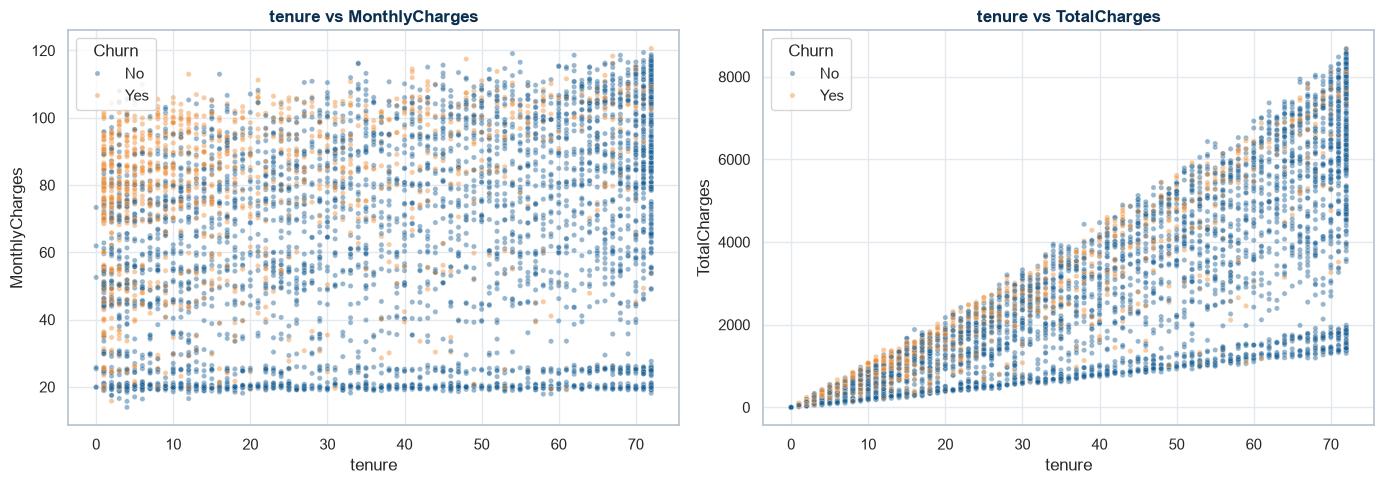

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))                          # dos gráficos de dispersión
for ax, eje_y in zip(axes, ['MonthlyCharges', 'TotalCharges']):          # tenure contra cada monto
    sns.scatterplot(data=train, x='tenure', y=eje_y, hue=TARGET, hue_order=['No', 'Yes'],   # puntos coloreados por churn
                    palette=COLORES_CHURN, alpha=0.45, s=14, ax=ax)      # puntos semitransparentes
    ax.set_title(f'tenure vs {eje_y}')                                   # título
plt.tight_layout()                                                       # acomodo los paneles
guardar_figura('dispersion_numericas')                                   # guardo el PNG
plt.show()                                                               # muestro la figura

`TotalCharges` está muy correlacionada con `tenure` (Pearson 0,83; Spearman 0,89) y bastante con `MonthlyCharges` (0,65), porque por construcción es casi su producto. `tenure` y `MonthlyCharges` apenas se correlacionan (0,26), así que aportan información distinta. En la dispersión, los que se van se concentran con poca antigüedad y cargo alto, y `tenure` contra `TotalCharges` forma un abanico de rectas, una por nivel de cargo.

> **Decisión 12:** conservar `TotalCharges`, sabiendo que es casi redundante. En el notebook de machine learning usamos regresión logística regularizada y comparamos el modelo con y sin `TotalCharges`.
>
> **Justificación:** la colinealidad no empeora la predicción, pero vuelve inestables los coeficientes de un modelo lineal y obliga a interpretarlos con cuidado (James et al., 2023, sec. 3.3.3). La regularización L2 lo atenúa y a los árboles no les afecta. Si quitarla mejora o empeora el modelo lo decide la validación.

## 9.2 Redundancias entre categóricas

Calculamos la V de Cramér entre todos los pares de categóricas. Con tablas de 3×3 o 4×4 los umbrales de la sección 8.1 no se aplican tal cual, así que la usamos para comparar pares entre sí.

La celda llena una matriz simétrica con la V de cada par (1 en la diagonal) y la grafica como heatmap. Después imprime tres resúmenes: los cinco pares más asociados fuera del bloque de internet, la mayor V de `gender` con otra predictora y el rango de V dentro del bloque. Dos variables con V cercana a 1 repiten la misma información, y tras el one-hot generan dummies casi idénticas. Esperamos V altas entre las variables que comparten las categorías "No phone service" y "No internet service".

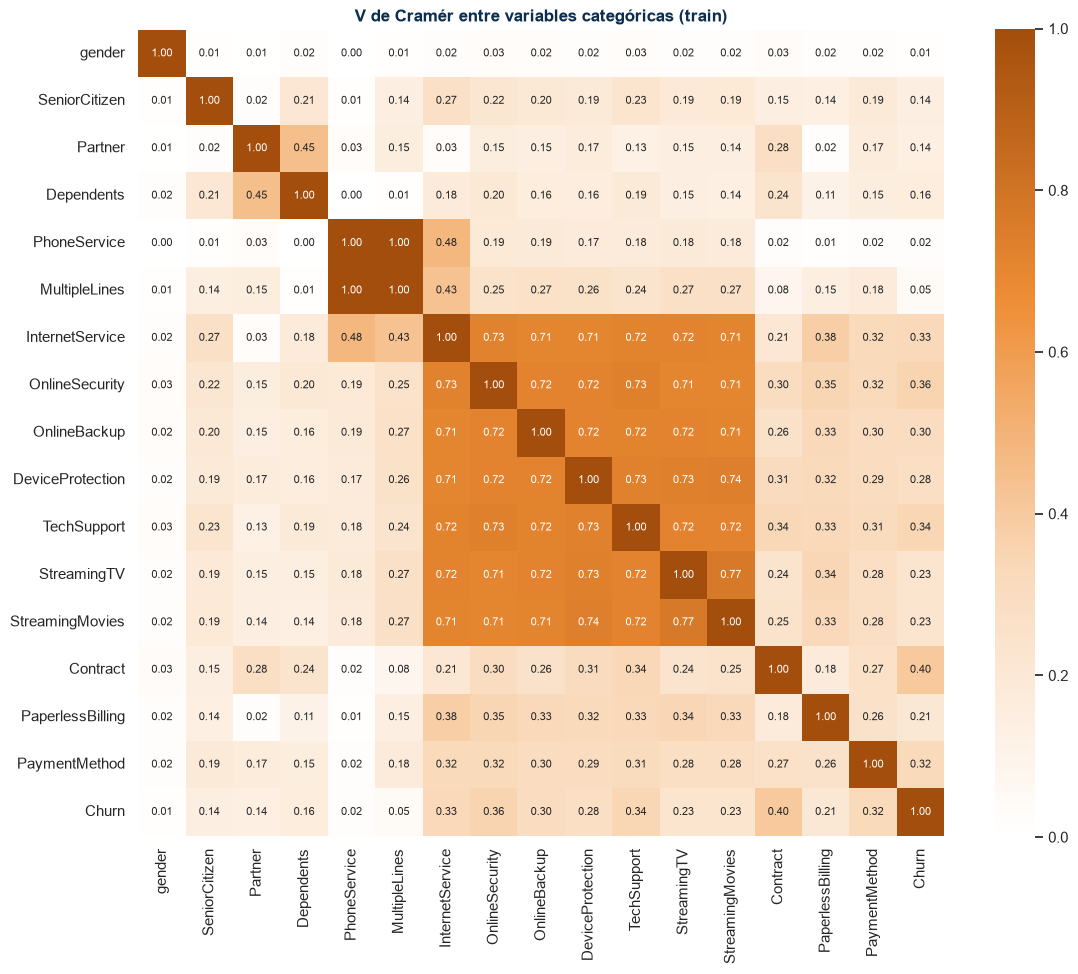

Pares más asociados fuera del bloque de internet:
 PhoneService - MultipleLines         1.000
PhoneService - InternetService       0.480
Partner - Dependents                 0.450
MultipleLines - InternetService      0.430
InternetService - PaperlessBilling   0.380
Máxima V de gender con otra predictora: 0.03
Bloque de internet, V entre 0.71 y 0.77


In [36]:
cols_v = COLS_CAT + [TARGET]                                             # 16 categóricas más el churn
matriz_v = pd.DataFrame(np.eye(len(cols_v)), index=cols_v, columns=cols_v)   # diagonal en 1
for a, b in combinations(cols_v, 2):                                     # recorro todos los pares
    matriz_v.loc[a, b] = matriz_v.loc[b, a] = cramers_v(train[a], train[b])   # la matriz es simétrica

fig, ax = plt.subplots(figsize=(13, 10.5))                               # figura grande
sns.heatmap(matriz_v, annot=True, fmt='.2f', cmap=CMAP_RIESGO, vmin=0, vmax=1, annot_kws={'size': 8},   # matriz de V
            square=True, ax=ax)                                          # matriz con el valor en cada celda
ax.set_title('V de Cramér entre variables categóricas (train)')         # título
guardar_figura('cramers_v_categoricas')                                  # guardo el PNG
plt.show()                                                               # muestro la figura

pares_v = pd.Series({f'{a} - {b}': matriz_v.loc[a, b] for a, b in combinations(COLS_CAT, 2)   # pares entre predictoras
                     if not {a, b} <= set(['InternetService'] + ADICIONALES)})              # fuera del bloque de internet
print('Pares más asociados fuera del bloque de internet:\n', pares_v.sort_values(ascending=False).head(5).round(2).to_string())   # los cinco mayores
print('Máxima V de gender con otra predictora:', matriz_v.loc['gender', COLS_CAT].drop('gender').max().round(2))   # gender no se asocia
print('Bloque de internet, V entre', matriz_v.loc['InternetService', ADICIONALES].min().round(2), 'y',   # InternetService con cada adicional
      matriz_v.loc[ADICIONALES, ADICIONALES].where(~np.eye(6, dtype=bool)).max().max().round(2))     # máximo entre adicionales

`PhoneService` y `MultipleLines` tienen V = 1,00: "No phone service" determina por completo a `PhoneService`. `InternetService` y los 6 adicionales forman un bloque con V de 0,71 a 0,77, y la asociación viene casi toda de la categoría compartida "No internet service". Tras el one-hot, las dummies "No internet service" de los 6 adicionales son idénticas entre sí y a `InternetService_No`: colinealidad perfecta en 7 columnas. Fuera de esos bloques, el par más alto es `PhoneService` con `InternetService` (0,48), por la regla de la oferta comercial, seguido de `Partner` con `Dependents` (0,45). `gender` no pasa de V = 0,03 con ninguna otra predictora.

> **Decisión 11:** codificar con `OneHotEncoder(drop='if_binary', handle_unknown='ignore')` dentro del pipeline, y comparar por validación cruzada la recodificación de "No internet service" a "No" en los 6 adicionales.
>
> **Justificación:** las nominales no tienen orden, y pasarlas a 1, 2, 3 inventaría una distancia entre categorías (James et al., 2023, sec. 3.3.1; Géron, 2022, cap. 2, *Handling Text and Categorical Attributes*; Murphy, 2022, sec. 1.5.3). Con `drop='if_binary'` las binarias quedan en una sola columna, y `handle_unknown='ignore'` evita errores si en test aparece una categoría que no estuvo en train. El bloque de 7 dummies iguales no daña a un modelo regularizado ni a un árbol, pero probablemente domine una componente del PCA. Recodificar es *stateless* y no pierde información, porque `InternetService_No` la conserva.

## 9.3 Interacciones con el churn

Hay interacción cuando el efecto de una variable sobre el churn cambia según el valor de otra. Cruzamos las variables más asociadas con tablas pivote (VanderPlas, 2016, cap. 3, *Pivot Tables*), con la cantidad de clientes de cada celda. El gráfico de líneas muestra intervalos del 95% por bootstrap (James et al., 2023, sec. 5.2), y en las celdas chicas los complementamos con el intervalo de Wilson (Wilson, 1927), que sigue siendo informativo cuando no hay bajas. El efecto de la fibra frente a DSL dentro de cada contrato lo medimos con el odds ratio y su intervalo de Woolf (Woolf, 1955).

La primera celda arma dos gráficos. A la izquierda, un heatmap con la tasa de churn por contrato y tipo de internet, con la cantidad de clientes de cada celda. A la derecha, la tasa por tramo de antigüedad para cada contrato, con intervalos por bootstrap; la semilla fija hace que esos intervalos se repitan en cada ejecución. Si no hubiera interacción, la diferencia entre columnas del heatmap sería la misma en todas las filas (en puntos porcentuales), y las líneas del gráfico irían paralelas.

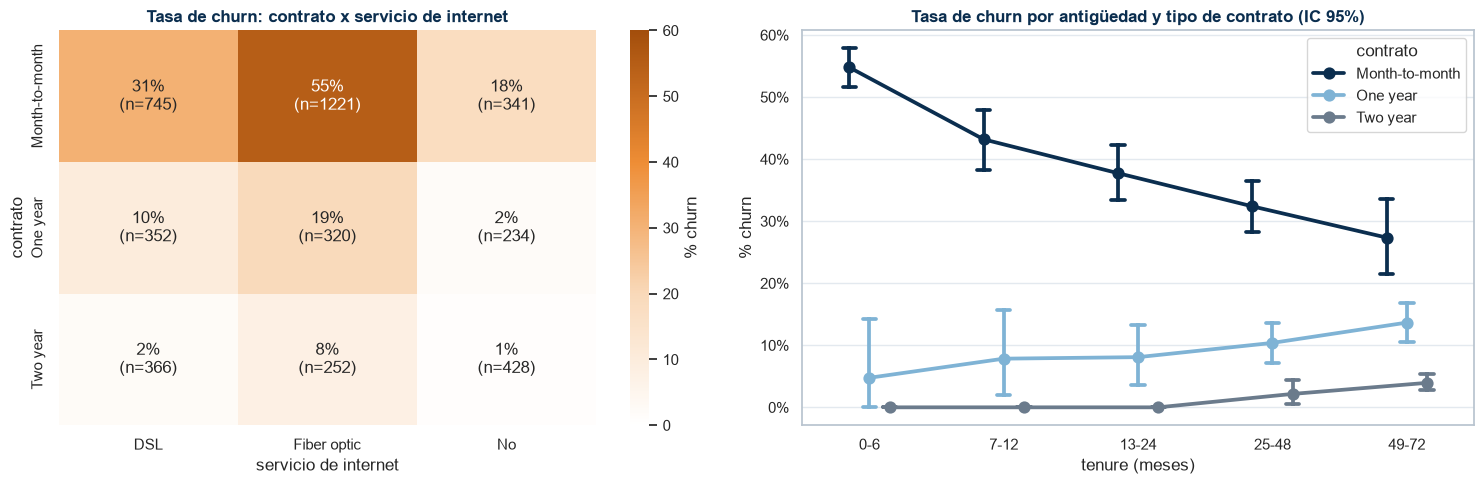

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))                          # dos paneles
tasa_ci = train.pivot_table(index='Contract', columns='InternetService', values='churn_num', aggfunc='mean') * 100   # tasa por celda
n_ci = train.pivot_table(index='Contract', columns='InternetService', values='churn_num', aggfunc='count')   # clientes por celda
etiquetas = tasa_ci.round(0).astype(int).astype(str) + '%\n(n=' + n_ci.astype(int).astype(str) + ')'   # texto de cada celda
sns.heatmap(tasa_ci, annot=etiquetas, fmt='', cmap=CMAP_RIESGO, vmin=0, vmax=60, ax=axes[0],   # tasa por contrato e internet
            cbar_kws={'label': '% churn'})                               # heatmap con tasa y n
axes[0].set_title('Tasa de churn: contrato x servicio de internet')     # título
axes[0].set_xlabel('servicio de internet')                               # eje x
axes[0].set_ylabel('contrato')                                           # eje y
datos_linea = train.assign(tramo=tramos).dropna(subset=['tramo', 'Contract'])   # agrego el tramo y saco NaN
sns.pointplot(data=datos_linea, x='tramo', y='churn_num', hue='Contract', errorbar=('ci', 95), seed=SEED,   # una línea por contrato con IC
              hue_order=['Month-to-month', 'One year', 'Two year'], palette=[AZUL_OSCURO, CELESTE, GRIS],   # azul UTN y naranja quedan para se queda / se va
              dodge=0.3, capsize=0.1, ax=axes[1])   # separo las líneas para que no se pisen
axes[1].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))   # eje en porcentaje
axes[1].set_title('Tasa de churn por antigüedad y tipo de contrato (IC 95%)')   # título
axes[1].set_xlabel('tenure (meses)')                                     # eje x
axes[1].set_ylabel('% churn')                                            # eje y
axes[1].legend(title='contrato')                                         # leyenda
plt.tight_layout()                                                       # acomodo los paneles
guardar_figura('interacciones_churn')                                    # guardo el PNG
plt.show()                                                               # muestro la figura

Para saber si el efecto de la fibra cambia con el contrato, medimos el odds ratio de fibra contra DSL dentro de cada contrato. Las odds de un grupo son sus bajas divididas por los que se quedan, y el odds ratio es el cociente entre las odds de los dos grupos. Un valor de 2 indica que con fibra las odds de irse son el doble que con DSL. El intervalo de Woolf se calcula en escala logarítmica, con error estándar `√(1/a + 1/b + 1/c + 1/d)` sobre las cuatro celdas de la tabla. Si los tres odds ratio son parecidos, en la escala de las odds no hay indicio de interacción.

In [38]:
bajas = train.pivot_table(index='Contract', columns='InternetService', values='churn_num', aggfunc='sum')   # bajas por celda
quedan = n_ci - bajas                                          # clientes que se quedan por celda
log_or = np.log(bajas['Fiber optic'] / quedan['Fiber optic']) - np.log(bajas['DSL'] / quedan['DSL'])   # log del odds ratio
se = np.sqrt(1 / bajas['Fiber optic'] + 1 / quedan['Fiber optic'] + 1 / bajas['DSL'] + 1 / quedan['DSL'])   # error estándar (Woolf)
print('Odds ratio fibra contra DSL, por contrato, con IC 95% de Woolf:')   # encabezado
print(pd.DataFrame({'bajas DSL': bajas['DSL'], 'OR': np.exp(log_or), 'IC inf': np.exp(log_or - 1.96 * se),   # OR y límite inferior
                    'IC sup': np.exp(log_or + 1.96 * se)}).round(2))   # muestro la tabla

Odds ratio fibra contra DSL, por contrato, con IC 95% de Woolf:
                bajas DSL    OR  IC inf  IC sup
Contract                                       
Month-to-month        228 2.750   2.270   3.330
One year               36 2.110   1.360   3.280
Two year                9 3.420   1.530   7.640


Que los intervalos se superpongan no es un test formal. La celda siguiente aplica el test de homogeneidad de Woolf (1955), que usa los mismos log odds ratio y errores estándar. Compara cada log OR con su promedio ponderado por el inverso de la varianza; si los tres son iguales, el estadístico sigue una chi-cuadrado con 2 grados de libertad. Esperamos un p-valor alto.

In [39]:
peso = 1 / se ** 2                                             # inverso de la varianza de cada log OR
log_or_comun = (peso * log_or).sum() / peso.sum()              # log OR común, promedio ponderado
q_woolf = (peso * (log_or - log_or_comun) ** 2).sum()          # estadístico de homogeneidad
print(f'OR común: {np.exp(log_or_comun):.2f} | test de homogeneidad de Woolf: chi2 = {q_woolf:.2f}, '   # resultado del test
      f'gl = {len(peso) - 1}, p = {stats.chi2.sf(q_woolf, len(peso) - 1):.3f}')   # p-valor con k - 1 grados de libertad

OR común: 2.67 | test de homogeneidad de Woolf: chi2 = 1.54, gl = 2, p = 0.463


La celda siguiente imprime las tasas que hay detrás del gráfico de líneas. En las celdas con pocos clientes, el bootstrap falla cuando no hay bajas: todas las remuestras dan 0% y el intervalo queda con ancho cero. Por eso, en las celdas con menos de 60 clientes calculamos el intervalo de Wilson, que invierte el test de una proporción y da un rango razonable aun con 0 bajas.

In [40]:
n_tc = datos_linea.pivot_table(index='Contract', columns='tramo', values='churn_num', aggfunc='count', observed=True)   # clientes por celda
b_tc = datos_linea.pivot_table(index='Contract', columns='tramo', values='churn_num', aggfunc='sum', observed=True)     # bajas por celda
print('\nTasa de churn (%) por contrato y tramo:\n', (b_tc / n_tc * 100).round(1))   # lo que hay detrás del gráfico de líneas
print('\nIC 95% de Wilson en las celdas antigüedad x contrato con menos de 60 clientes:')   # encabezado
for (contrato, tramo), n_celda in n_tc.stack().items():        # recorro las celdas
    if n_celda < 60:                                           # solo las chicas
        ic = stats.binomtest(int(b_tc.loc[contrato, tramo]), int(n_celda)).proportion_ci(method='wilson')   # intervalo de Wilson
        print(f'  {contrato:15s} {str(tramo):6s} {int(b_tc.loc[contrato, tramo]):2d} de {int(n_celda):3d}: {ic.low * 100:4.1f}% a {ic.high * 100:4.1f}%')   # una línea por celda


Tasa de churn (%) por contrato y tramo:
 tramo             0-6   7-12  13-24  25-48  49-72
Contract                                         
Month-to-month 54.800 43.200 37.700 32.400 27.400
One year        4.800  7.800  8.100 10.400 13.700
Two year        0.000  0.000  0.000  2.200  3.900

IC 95% de Wilson en las celdas antigüedad x contrato con menos de 60 clientes:
  One year        0-6     1 de  21:  0.8% a 22.7%
  One year        7-12    4 de  51:  3.1% a 18.5%
  Two year        0-6     0 de  22:  0.0% a 14.9%
  Two year        7-12    0 de  24:  0.0% a 13.8%
  Two year        13-24   0 de  57:  0.0% a  6.3%


El cheque electrónico tiene la tasa de churn más alta entre los medios de pago (sección 8.1), pero podría deberse a que lo usan sobre todo clientes mes a mes. Para separar los dos efectos, la celda muestra qué parte de cada medio de pago está en cada contrato y la tasa de churn de cada medio de pago dentro de cada contrato. Si la diferencia persiste dentro de un mismo contrato, el medio de pago aporta información propia.

In [41]:
print('% de cada medio de pago por contrato:')   # encabezado
print((pd.crosstab(train['PaymentMethod'], train['Contract'], normalize='index') * 100).round(0).astype(int))   # composición por contrato, en % enteros
print('\nTasa de churn (%) por medio de pago dentro de cada contrato:')   # encabezado
print(train.pivot_table(index='PaymentMethod', columns='Contract', values='churn_num', aggfunc='mean').mul(100).round(1))   # tasa dentro de cada contrato

% de cada medio de pago por contrato:
Contract                   Month-to-month  One year  Two year
PaymentMethod                                                
Bank transfer (automatic)              37        26        37
Credit card (automatic)                37        26        37
Electronic check                       78        15         7
Mailed check                           55        22        23

Tasa de churn (%) por medio de pago dentro de cada contrato:
Contract                   Month-to-month  One year  Two year
PaymentMethod                                                
Bank transfer (automatic)          32.300     8.500     4.500
Credit card (automatic)            33.300    10.400     2.900
Electronic check                   55.300    19.000     8.000
Mailed check                       32.400     6.700     0.500


Por último cruzamos antigüedad y tipo de internet en un heatmap, con la cantidad de clientes de cada celda. Queremos saber si la fibra tiene más bajas en todos los tramos o solo en los primeros meses, cuando todos los clientes se van más.

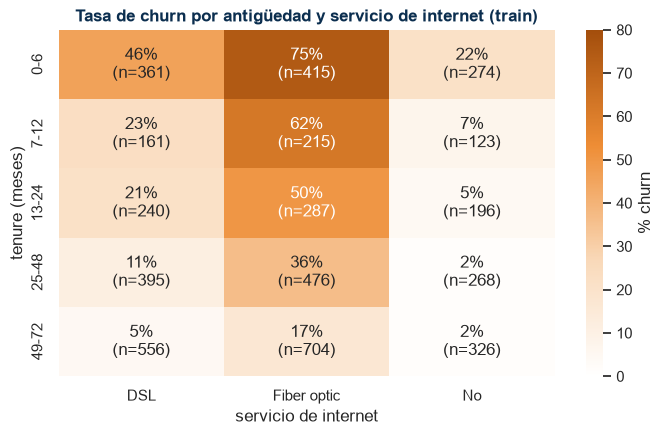

In [42]:
datos_ti = train.assign(tramo=tramos).dropna(subset=['tramo', 'InternetService'])      # train con tramo e internet
tabla_ti = datos_ti.pivot_table(index='tramo', columns='InternetService', values='churn_num',   # tasa por tramo e internet
                                aggfunc='mean', observed=True) * 100                   # tasa por tramo e internet
n_ti = datos_ti.pivot_table(index='tramo', columns='InternetService', values='churn_num',   # clientes por tramo e internet
                            aggfunc='count', observed=True)                            # clientes por celda
etiquetas_ti = tabla_ti.round(0).astype(int).astype(str) + '%\n(n=' + n_ti.astype(str) + ')'   # texto de cada celda
fig, ax = plt.subplots(figsize=(8, 4.5))                                               # figura mediana
sns.heatmap(tabla_ti, annot=etiquetas_ti, fmt='', cmap=CMAP_RIESGO, vmin=0, vmax=80, ax=ax,   # heatmap de tasas
            cbar_kws={'label': '% churn'})                                             # heatmap con tasa y n
ax.set_title('Tasa de churn por antigüedad y servicio de internet (train)')           # título
ax.set_xlabel('servicio de internet')                                                  # eje x
ax.set_ylabel('tenure (meses)')                                                        # eje y
guardar_figura('churn_tenure_internet')                                                # guardo el PNG
plt.show()                                                                             # muestro la figura

- **Contrato × internet.** Mes a mes con fibra llega al 55% de churn y es el grupo más grande (1.221 clientes de train). Con dos años, aun con fibra, baja a 8%. En puntos porcentuales las dos variables se combinan, pero en la escala de las odds el efecto de la fibra frente a DSL es parecido en los tres contratos (odds ratio 2,7, 2,1 y 3,4). El 3,4 de los contratos de dos años sale de solo 9 bajas con DSL: su intervalo va de 1,5 a 7,6 y se superpone con los otros dos. La superposición sola no es un test, pero el test de homogeneidad de Woolf tampoco rechaza que los tres sean iguales (p = 0,46). Un odds ratio común es lo que supone una regresión logística sin términos de interacción (James et al., 2023, sec. 3.3.2), así que la tabla no alcanza para exigirlos y lo decide la validación.
- **Antigüedad × contrato.** En el mes a mes el churn baja de 55% a 27% con la antigüedad, con cientos de clientes por tramo. En el anual sube de 8% a 14% entre los tramos con suficientes clientes. El 5% del primer tramo anual sale de 1 baja en 21 clientes, y los 0% de los contratos de dos años, de grupos de 22 a 57; el bootstrap les da un intervalo de ancho cero, que no es certeza. Con Wilson, 0 bajas en 22 clientes es compatible con una tasa de hasta 15%, y el 5% del primer tramo anual va de 1% a 23%.
- **Medio de pago × contrato.** El 78% de los que pagan con cheque electrónico está en mes a mes (contra 37% con débito o tarjeta automáticos), así que parte de su 47% de churn se explica por el contrato. El resto persiste: dentro del mes a mes el cheque electrónico llega a 55% contra 32% a 33% de los otros medios, y en el anual a 19% contra 7% a 10%.
- **Antigüedad × internet.** La fibra tiene el churn más alto en todos los tramos: 75% hasta los 6 meses contra 46% con DSL y 22% sin internet, y 17% contra 5% y 2% después de 4 años. Todas las celdas tienen más de 120 clientes.

La asociación de una variable con el churn cambia según el valor de otra, al menos en puntos porcentuales. Los árboles y los ensambles capturan esas combinaciones por sí solos; en la regresión logística se pueden agregar interacciones si la validación cruzada lo justifica.

## 9.4 Variable derivada: cantidad de servicios adicionales

En la sección 8.1, cada adicional de protección se asoció con menos bajas. Si el efecto se acumula, la cantidad de adicionales contratados podría resumir en una sola variable lo que hoy está repartido en seis. La celda cuenta, para cada cliente con internet, cuántos adicionales tiene en "Yes" y calcula, para cada cantidad, el número de clientes, la tasa de churn, la antigüedad mediana y la proporción con contrato mes a mes. Las dos últimas columnas sirven para ver si la cantidad de servicios se mueve junto con variables que ya sabemos asociadas al churn. Esperamos que la tasa baje a medida que sube la cantidad.

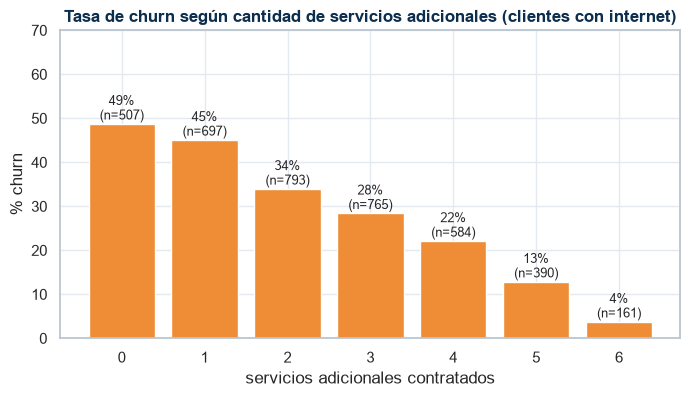

n_adicionales,0,1,2,3,4,5,6
clientes,507,697,793,765,584,390,161
churn,0.49,0.45,0.34,0.28,0.22,0.13,0.04
tenure_mediana,4,11,24,38,53,63,70
% mes a mes,0.96,0.89,0.73,0.54,0.33,0.13,0.03


In [43]:
con_internet = train[train['InternetService'].isin(['DSL', 'Fiber optic'])].copy()      # solo clientes con internet
con_internet['n_adicionales'] = (con_internet[ADICIONALES] == 'Yes').sum(axis=1)        # cuántos "Yes" tiene
resumen = con_internet.groupby('n_adicionales').agg(clientes=('churn_num', 'size'), churn=('churn_num', 'mean'),   # n, tasa y antigüedad
                                                    tenure_mediana=('tenure', 'median'))   # antigüedad mediana
resumen['% mes a mes'] = con_internet.groupby('n_adicionales')['Contract'].apply(   # proporción mes a mes
    lambda s: (s.dropna() == 'Month-to-month').mean())         # contrato según cantidad de servicios

fig, ax = plt.subplots(figsize=(8, 4))                                               # figura mediana
ax.bar(resumen.index, resumen['churn'] * 100, color=NARANJA)                         # una barra por cantidad
for cantidad, (tasa_cant, n_cant) in zip(resumen.index, zip(resumen['churn'], resumen['clientes'])):   # etiqueta en cada barra
    ax.text(cantidad, tasa_cant * 100 + 1, f'{tasa_cant * 100:.0f}%\n(n={n_cant})', ha='center', fontsize=9)   # tasa y n arriba de la barra
ax.set_ylim(0, 70)                                                                   # rango del eje y
ax.set_title('Tasa de churn según cantidad de servicios adicionales (clientes con internet)')   # título
ax.set_xlabel('servicios adicionales contratados')                                   # eje x
ax.set_ylabel('% churn')                                                             # eje y
guardar_figura('churn_por_servicios_adicionales')                                    # guardo el PNG
plt.show()                                                                           # muestro la figura
resumen.T.style.format('{:.2f}').format('{:.0f}', subset=pd.IndexSlice[['clientes', 'tenure_mediana'], :])   # conteos y medianas sin decimales

Entre los clientes con internet, el churn baja casi en línea recta con la cantidad de adicionales: 49% sin ninguno, 34% con dos, 22% con cuatro y 4% con los seis. Pero la cantidad acompaña a la antigüedad (mediana de 4 meses sin adicionales y de 70 con los seis) y al contrato (96% en mes a mes sin adicionales, 3% con los seis): los clientes acumulan servicios con el tiempo. Para predecir no es un problema; para el informe es una asociación y no el efecto de cada servicio. En este cálculo un adicional faltante cuenta como "no contratado", por lo que en el notebook de machine learning la variable se calcula después de imputar.

> **Decisión 15:** proponer `n_adicionales` y, como opción, tramos de `tenure`, e incorporarlas solo si mejoran la validación cruzada.
>
> **Justificación:** pueden resumir un patrón (la cantidad de servicios) o la no linealidad de `tenure` que un modelo lineal no capta solo (James et al., 2023, sec. 3.3.2). También pueden ser redundantes con las variables originales, como sugiere su relación con la antigüedad y el contrato. Las dos son *stateless*, así que se agregan con un `FunctionTransformer` sin fuga (Géron, 2022, cap. 2, *Custom Transformers*); `n_adicionales` va después del imputador de los adicionales y antes del one-hot.

> **Decisión 16:** el PCA del notebook de machine learning va dentro del pipeline, después de imputar, codificar y escalar.
>
> **Justificación:** el PCA aprende medias, varianzas y componentes de los datos, necesita datos sin `NaN` y en escalas comparables (James et al., 2023, sec. 12.2.4), y tiene que ajustarse solo con train. Dos resultados de este análisis lo afectan: el bloque de 7 dummies idénticas (sección 9.2) y la diferencia de varianza entre las numéricas escaladas y las dummies (sección 10.2).

# 10. Conclusiones

**Calidad de los datos.** El dataset es coherente: no tiene duplicados, categorías mal escritas ni valores imposibles, y las reglas entre columnas se cumplen siempre. Los problemas de formato son `TotalCharges` como texto (11 blancos de clientes nuevos) y `SeniorCitizen` como número. El problema serio son los faltantes: 14 variables pierden entre el 13% y el 17%, y solo el 12% de los clientes tiene la fila completa. Para el mecanismo original no encontramos evidencia en contra de MCAR. Las reglas entre columnas recuperan 3.398 valores (24%) sin fuga, y el resto se imputa dentro del pipeline. Después de las reglas, los faltantes que quedan en los servicios pasan a ser MAR, porque pertenecen a clientes que tienen el servicio (sección 6.5).

**El churn.** Se va el 26,5% de los clientes, que representan el 30,7% de la facturación mensual. Las variables más asociadas son el contrato (42% en mes a mes contra 3% en dos años) y la antigüedad (53% hasta 6 meses contra 10% después de 4 años, con relación no lineal). Les siguen la falta de seguridad online y soporte técnico, la fibra óptica (la tasa más alta en todos los tramos de antigüedad) y el cheque electrónico, que mantiene más bajas aun dentro de cada contrato. `gender` y `PhoneService` no se asocian con el churn; `PhoneService` es redundante con `MultipleLines` y `TotalCharges` casi lo es con `tenure × MonthlyCharges`.

**Perfil de riesgo.** El cliente con más probabilidad de figurar como baja es nuevo, con contrato mes a mes y fibra, sin seguridad online ni soporte técnico, y paga con cheque electrónico. Las acciones a evaluar son migrar a contratos más largos, sumar servicios de protección y promover el débito automático. Son asociaciones y no relaciones causales, y varias se superponen con la antigüedad: medir si una acción retiene clientes requiere un experimento.

## 10.1 Registro de decisiones

La columna "Dónde se aplica" distingue cuatro casos. Lo que se calcula fila por fila sin aprender de los datos (*stateless*) va antes del pipeline y lo aplica `clusterai_guillermo_inostroza_manipulacion.ipynb`, que guarda `data/telco_manipulado.csv`. Lo que aprende de los datos (*stateful*) va dentro del pipeline de `clusterai_guillermo_inostroza_machine_learning.ipynb`, ajustado solo con train en cada fold. "Criterio general" marca formas de trabajar que no son un paso de código, y "Evaluación" marca cómo se comparan y eligen los modelos.

| # | Decisión | Evidencia | Dónde se aplica |
|---|---|---|---|
| 1 | Eliminar `Unnamed: 0`; `customerID` solo como identificador | Copia del índice; un ID único se memoriza | Antes del pipeline (stateless) |
| 2 | `TotalCharges` a número; los 11 blancos pasan a 0 | Los blancos son los clientes con `tenure = 0` | Antes del pipeline (stateless) |
| 3 | `SeniorCitizen` a No/Yes | Mismo formato que las demás binarias | Antes del pipeline (stateless) |
| 4 | Split 80/20 estratificado, `random_state=42`, guardado en `data/particion_train_test.csv` | Evita el *data snooping*; 26,5% de churn en los dos conjuntos | Evaluación (partición hecha en este notebook) |
| 5 | No usar `dropna` | Solo el 12% de las filas está completo | Criterio general |
| 6 | Faltantes originales MCAR, sin indicadoras | Independientes, ninguna brecha de churn significativa con Bonferroni, 0 de 266 tests con Bonferroni, AUC ≈ 0,5 | Criterio general |
| 7 | Reglas R1 a R9 | Exactas o con error 15 a 32 veces menor que la mediana; recuperan 3.398 valores | Antes del pipeline (stateless) |
| 8 | Mediana en numéricas; moda contra "Desconocido" por CV en categóricas; `KNNImputer` como sensibilidad | La moda diluye la asociación de `Contract` (42,4% a 38,1%) | Dentro del pipeline (stateful) |
| 9 | No eliminar outliers | El criterio de 1,5·IQR no marca ninguno; todos los valores son plausibles | Criterio general |
| 10 | `StandardScaler`; `log1p(TotalCharges)` opcional | Escalas muy distintas; `TotalCharges` asimétrica (0,95) | Dentro del pipeline (stateful); `log1p` es stateless |
| 11 | `OneHotEncoder(drop='if_binary', handle_unknown='ignore')`; comparar recodificar "No internet service" a "No" | Nominales sin orden; 7 dummies idénticas | Dentro del pipeline (stateful); la recodificación es stateless |
| 12 | Regularizar y comparar con y sin `TotalCharges` | Pearson 0,83 con `tenure`; casi igual al producto | Evaluación (selección por CV) |
| 13 | Elegir por ROC-AUC; umbral por matriz de costos con CV en train; bases "nadie se va", "oferta a todos" y logística sin ajuste | 73,5% de accuracy sin aprender nada; los dos errores no cuestan lo mismo | Evaluación |
| 14 | CV estratificada de 5 folds en train; test una sola vez | Error estándar del recall en test de hasta 2,6 puntos | Evaluación |
| 15 | `n_adicionales` y tramos de `tenure` solo si mejoran la CV | Churn de 49% a 4% según adicionales, pero se mueve con antigüedad y contrato | Dentro del pipeline: stateless, pero `n_adicionales` necesita los adicionales imputados (`FunctionTransformer` después del imputador) |
| 16 | PCA después de imputar, codificar y escalar | Aprende de los datos y necesita escalas comparables | Dentro del pipeline (stateful) |
| 17 | Evaluar por CV quitar `gender` y `PhoneService` | V = 0,01 y 0,02 con el churn; `PhoneService` redundante (V = 1) | Evaluación (selección por CV) |
| 18 | Costos: pérdida de 897 (12 meses del cargo medio de los que se van), oferta de 120 (13% del año); umbral base 0,134 y tabla de sensibilidad | El costo no está en los datos; el umbral depende solo del cociente entre la oferta y lo que se recupera | Evaluación |

## 10.2 Lo que queda para el modelado

El notebook de machine learning parte de `data/telco_manipulado.csv`, que ya trae aplicadas las decisiones 1, 2, 3 y 7 y la partición de la decisión 4 como columna `conjunto`, sin volver a llamar a `train_test_split`. Quedan por resolver ahí:

1. **Escala antes del PCA.** Si se escalan solo las 3 numéricas (varianza 1) y quedan sin escalar las dummies en 0/1 (varianza p(1-p), a lo sumo 0,25), el PCA queda dominado por las numéricas. Con las 16 categóricas, `drop='if_binary'` y la moda salen 37 dummies; la cantidad final depende de la imputación, la recodificación y las variables que se eliminen. Si se escala todo, las categorías raras ganan peso (James et al., 2023, sec. 12.2.4).
2. **"No internet service" en 6 columnas.** Comparar el modelo base con la recodificación; para el PCA es probable que convenga recodificar.
3. **Imputación.** Elegir entre moda y "Desconocido" por CV y controlar que el imputador elegido no devuelva "sin servicio" a clientes con el servicio (sección 6.5). `KNNImputer`, después del one-hot, solo como sensibilidad.
4. **Árboles con faltantes.** En scikit-learn 1.9, `DecisionTreeClassifier` y `RandomForestClassifier` aceptan `NaN` en las numéricas: comparar esa opción contra imputar.
5. **Variables derivadas.** `n_adicionales` después del imputador de los adicionales y antes del one-hot; tramos de `tenure` como alternativa.
6. **Costos.** Elegir el umbral por CV con el escenario base de la decisión 18 e informar el umbral y el costo total en los escenarios de la sección 8.3.

# 11. Referencias

**Bibliografía principal**

1. James, G., Witten, D., Hastie, T., Tibshirani, R. y Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*. Springer. Secciones 3.3.1, 3.3.2, 3.3.3, 4.4.2, cap. 5 (5.2), 6.2.2, cap. 11, 12.2.4, 12.3, 13.1 y 13.3.2.
2. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly. Capítulos 2 y 3.
3. VanderPlas, J. (2016). *Python Data Science Handbook*. O'Reilly. Capítulo 3.
4. Murphy, K. P. (2022). *Probabilistic Machine Learning: An Introduction*. MIT Press. Secciones 1.5.3, 1.5.5, 5.1.2.2 y 5.1.4.4.

**Otros papers y herramientas**

5. Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences* (2.ª ed.). Lawrence Erlbaum.
6. Cramér, H. (1946). *Mathematical Methods of Statistics*. Princeton University Press.
7. Gupta, S., Hanssens, D., Hardie, B., Kahn, W., Kumar, V., Lin, N., Ravishanker, N. y Sriram, S. (2006). Modeling customer lifetime value. *Journal of Service Research*, 9(2), 139-155.
8. Mann, H. B. y Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. *The Annals of Mathematical Statistics*, 18(1), 50-60.
9. Pearson, K. (1900). On the criterion that a given system of deviations from the probable in the case of a correlated system of variables is such that it can be reasonably supposed to have arisen from random sampling. *Philosophical Magazine*, 50(302), 157-175.
10. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
11. Spearman, C. (1904). The proof and measurement of association between two things. *The American Journal of Psychology*, 15(1), 72-101.
12. Verbraken, T., Verbeke, W. y Baesens, B. (2013). A novel profit maximizing metric for measuring classification performance of customer churn prediction models. *IEEE Transactions on Knowledge and Data Engineering*, 25(5), 961-973.
13. Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association*, 22(158), 209-212.
14. Woolf, B. (1955). On estimating the relation between blood group and disease. *Annals of Human Genetics*, 19(4), 251-253.